# CISC7204 Class E / Team 01 — Visualisation Notebook (fully implemented)

**Topic.** Macau visitor arrivals, hotel occupancy, and bus ridership: measuring the coupling, the seasonal shape, and the spatial/temporal mismatch between demand and supply.

**This file is the executed companion of `CISC7204_ClassE_Team01_Visualization_Methods.ipynb`.** Every code cell below is complete and runs top to bottom with no placeholders. The methods notebook states *what must be true*; this notebook *produces the evidence*.

**Window convention (revised).**
* The **36-month core window 2023-01 to 2025-12** remains the estimation window for level statistics, correlations and the per-visitor intensity trend. 2020-2022 stays excluded (border policy, not demand).
* **2026 months (2026-01 to 2026-09) are now used as an out-of-sample seasonal test bed**, not merely as the supply snapshot for Figures 2 and 3. The question the 2026 months answer is: *does the 2023-2025 seasonal shape recur, and at what level?* Section 8 (RQ2) does this explicitly, with the 2026 within-year index computed on a 9-month base and every comparison to the base years restricted to the shared months 1-9.
* Figures 2 and 3 still use the 2026 half-hour/hourly supply data, because district-hour demand is only distributed for that year.

**Outputs.** All figures are written to `output/figures` at 200 dpi, with a source/footprint caption burned into the PNG.

## 1. Environment, paths, palette

Colour-blind-safe Okabe-Ito palette, CJK-capable font stack, and one shared `stamp()` helper so that every figure carries its own provenance.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as mticker
from matplotlib.patches import Rectangle
import seaborn as sns
from scipy import stats
from IPython.display import display

warnings.filterwarnings("ignore")

BASE = Path(r"C:\Users\user\Documents\cisc7204\Project\Github\CISC7204-ClassE-Team01-2026GitHub")
DATA = BASE / "data_processed"
RAW  = BASE / "Dataset"
FIG  = BASE / "notebooks" / "figures_pending cross check"
FIG.mkdir(parents=True, exist_ok=True)

# Okabe-Ito colour-blind-safe palette
BLUE, ORANGE, GREEN, RED = "#0072B2", "#E69F00", "#009E73", "#D55E00"
PURPLE, SKY, GREY, YELLOW = "#CC79A7", "#56B4E9", "#8C8C8C", "#F0E442"
YEAR_COLORS = {2023: BLUE, 2024: ORANGE, 2025: GREEN, 2026: RED}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "grid.linewidth": 0.6,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

SOURCE = "Source: MGTO Data Plus / DSEC visitor arrivals / DSAT bus statistics, retrieved 2026-11-04."

def stamp(fig, note, source=SOURCE):
    """Burn a provenance + footprint caption into the bottom-left of a figure."""
    fig.text(0.004, 0.004, f"{note}  |  {source}", fontsize=6.8, color="#555555",
             ha="left", va="bottom")

def save_fig(fig, name):
    path = FIG / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    print(f"saved  {name}")
    return path

print("=" * 88)
print("DATA exists :", DATA.exists(), "   RAW exists :", RAW.exists())
print("FIG         :", FIG)
print("versions    : pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)
print("=" * 88)

DATA exists : True    RAW exists : True
FIG         : C:\Users\user\Documents\cisc7204\Project\Github\CISC7204-ClassE-Team01-2026GitHub\notebooks\figures_pending cross check
versions    : pandas 3.0.3 | numpy 2.4.6 | matplotlib 3.11.0 | seaborn 0.13.2


## 2. Data audit gate — structural checks

Load every file once, then run an explicit checklist. Nothing downstream is allowed to run if a structural check fails, so a silent row-count change in the source cannot quietly propagate into a figure.

In [2]:
panel  = pd.read_csv(DATA / "monthly_panel_2023_01_2026_09.csv")
detail = pd.read_csv(DATA / "monthly_detail_2023_01_2026_09.csv")
qpanel = pd.read_csv(DATA / "quarterly_panel_2023Q1_2026Q3.csv")
qdet   = pd.read_csv(DATA / "quarterly_detail_2023Q1_2026Q3.csv")
seg    = pd.read_csv(RAW  / "visitors_2023_2026_summary.csv")
mkts   = pd.read_csv(RAW  / "visitors_2023_2026_by_market_summary.csv")
long   = pd.read_csv(DATA / "demand_monthly_arrivals.csv", parse_dates=["date"]).sort_values("date")
dh     = pd.read_csv(DATA / "analysis_dataset_master.csv")
dh26   = pd.read_csv(DATA / "demand_district_hour_2026.csv")
zone   = pd.read_csv(DATA / "match_zone_supply_demand.csv")
hourly = pd.read_csv(DATA / "match_hourly_profile.csv")
dmm    = pd.read_csv(DATA / "district_map_metrics.csv")
seas   = pd.read_csv(DATA / "monthly_seasonality_index.csv")
qa     = pd.read_csv(DATA / "qa_report.csv")

# --- canonical month index -----------------------------------------------------
panel["month_dt"] = pd.to_datetime(panel["month"] + "-01")
panel = panel.sort_values("month_dt").reset_index(drop=True)
panel["quarter_of_year"] = (panel["month_no"] - 1) // 3 + 1
panel["q"] = panel["year"].astype(str) + "Q" + panel["quarter_of_year"].astype(str)

TS = pd.Timestamp
WIN_START, WIN_END = TS("2023-01-01"), TS("2025-12-31")

audit = []
def rec(name, expected, observed, note=""):
    audit.append({"check": name, "expected": expected, "observed": observed,
                  "verdict": "PASS" if str(expected) == str(observed) else "FAIL",
                  "note": note})

rec("monthly panel rows", 45, len(panel), "2023-01 .. 2026-09")
rec("duplicate month keys", 0, int(panel["month"].duplicated().sum()))
rec("quarterly panel rows", 15, len(qpanel), "2023Q1 .. 2026Q3")
rec("district-hour master rows", 25920, len(dh), "24 districts x 24 h x 45 months")
rec("2026 district-hour rows", 4032, len(dh26), "24 districts x 24 h x 7 months")
rec("zone supply-demand rows", 3, len(zone), "Peninsula / Taipa & Cotai / Coloane")
rec("hourly profile rows", 24, len(hourly))
rec("long-run monthly rows", 225, len(long), "2008-01 .. 2026-09")

win = panel[(panel.month_dt >= WIN_START) & (panel.month_dt <= WIN_END)].copy()
rec("core-window rows", 36, len(win))
rec("core-window quarters", 12, win["q"].nunique())
rec("pandemic months inside window", 0,
    int(len(panel[(panel.month_dt >= TS("2020-01-01")) & (panel.month_dt <= TS("2022-12-31"))])))
_midx = win["year"] * 12 + win["month_no"]
rec("consecutive monthly steps", 35, int((_midx.diff().dropna() == 1).sum()),
    "36 consecutive months -> 35 unit steps")

audit_df = pd.DataFrame(audit)
display(audit_df)

# data-quality note carried over from qa_report.csv
display(qa)

,check,expected,observed,verdict,note
0,monthly panel rows,45,45,PASS,2023-01 .. 2026-09
1,duplicate month keys,0,0,PASS,
2,quarterly panel rows,15,15,PASS,2023Q1 .. 2026Q3
3,district-hour master rows,25920,25920,PASS,24 districts x 24 h x 45 months
4,2026 district-hour rows,4032,4032,PASS,24 districts x 24 h x 7 months
5,zone supply-demand rows,3,3,PASS,Peninsula / Taipa & Cotai / Coloane
6,hourly profile rows,24,24,PASS,
7,long-run monthly rows,225,225,PASS,2008-01 .. 2026-09
8,core-window rows,36,36,PASS,
9,core-window quarters,12,12,PASS,


,check,value,status,note
0,monthly panel rows (expected 45),45,PASS,2023-01 .. 2026-09
1,monthly panel duplicate months,0,PASS,one row per month
2,monthly panel missing months,0,PASS,no gap in the 45-month sequence
3,district-hour duplicates,0,PASS,year-to-date rule verified
4,district-hour balanced grid,1 month sizes / 576,PASS,24 districts x 24 hours
5,negative headcount values,0,PASS,counts are non-negative
6,zero headcount cells (%),0.0,INFO,night hours in low-traffic districts
7,hotel series completeness,45/45,PASS,DSEC hotel survey
8,bus series completeness,45/45,PASS,DSAT monthly statistics
9,arrivals outliers (|z| > 3 in 2023-2026),0,INFO,none expected inside the post-pandemic window


## 3. Audit gate — unit reconciliation and roll-up identity

Two hard identities must hold before any ratio is trusted:
1. **Unit identity.** `bus_daily_avg_trips_wan` is *ten-thousand trips per day*. Multiplying by 10,000 and by days-in-month must reproduce `bus_monthly_trips`.
2. **Roll-up identity.** Summing the 36 monthly rows inside each quarter must reproduce the quarterly table exactly (this is the check that catches a mis-aligned month index).

In [3]:
# --- 1. unit identity ----------------------------------------------------------
days = win["month_dt"].dt.days_in_month
implied = win["bus_daily_avg_trips_wan"] * 1e4 * days
unit_gap = (implied - win["bus_monthly_trips"]).abs() / win["bus_monthly_trips"]
unit_tbl = pd.DataFrame({
    "month": win["month"],
    "wan_per_day": win["bus_daily_avg_trips_wan"],
    "implied_monthly": implied.round(0).astype("int64"),
    "stored_monthly": win["bus_monthly_trips"].astype("int64"),
    "relative_gap": unit_gap.round(5),
})
print("max relative gap (wan/day x days_in_month vs stored monthly):", round(unit_gap.max(), 5))
print("months with gap > 0.001 :", int((unit_gap > 0.001).sum()))

# --- 2. roll-up identity -------------------------------------------------------
roll = win.groupby("q").agg(months=("month", "count"),
                            arrivals=("visitor_arrivals", "sum"),
                            guests=("hotel_guests", "sum"),
                            occ=("hotel_occ_pct", "mean"),
                            trips=("bus_monthly_trips", "sum"))
q36 = qpanel.set_index("quarter").loc[roll.index]
recon = pd.DataFrame({
    "months": roll["months"],
    "arr_rollup": roll["arrivals"], "arr_quarter": q36["visitor_arrivals_sum"],
    "gst_rollup": roll["guests"],   "gst_quarter": q36["hotel_guests_sum"],
    "trp_rollup": roll["trips"],    "trp_quarter": q36["bus_monthly_trips_sum"],
})
recon["arr_diff"] = (recon.arr_rollup - recon.arr_quarter).round(3)
recon["gst_diff"] = (recon.gst_rollup - recon.gst_quarter).round(3)
recon["trp_diff"] = (recon.trp_rollup - recon.trp_quarter).round(3)
display(recon)

exact = int(((recon.arr_diff == 0) & (recon.gst_diff == 0) & (recon.trp_diff == 0)).sum())
rec("quarters reproducing exactly", 12, exact, "sum of 3 monthly rows == quarterly row")
rec("quarterly rows flagged partial", 0, int((qdet["partial"] == "partial").sum()),
    "all 15 quarters complete, incl. 2026Q1-Q3")

# --- 3. missing-value register -------------------------------------------------
nulls = panel.isna().sum()
nulls = nulls[nulls > 0]
print("\nMissing values in the 45-month panel:")
print(nulls.to_string() if len(nulls) else "  none")
print("months where buses_in_service is unpublished:",
      panel.loc[panel["buses_in_service"].isna(), "month"].tolist())

rec("monthly panel columns fully populated (excl. buses_in_service)", 15,
    int((panel.drop(columns=["buses_in_service"]).isna().sum() == 0).sum()),
    "16 columns incl. 3 derived; only buses_in_service has gaps")

# --- gate ----------------------------------------------------------------------
audit_df = pd.DataFrame(audit)
display(audit_df.tail(8))
assert (audit_df["verdict"] == "PASS").all(), audit_df[audit_df["verdict"] == "FAIL"]
print("AUDIT GATE PASSED —", len(audit_df), "checks, 0 failures")

max relative gap (wan/day x days_in_month vs stored monthly): 0.0
months with gap > 0.001 : 0


,months,arr_rollup,arr_quarter,gst_rollup,gst_quarter,trp_rollup,trp_quarter,arr_diff,gst_diff,trp_diff
q,,,,,,,,,,
2023Q1,3,4948358.0,4948358,2705380.0,2705380,49304200.0,49304200,0.0,0.0,0.0
2023Q2,3,6697519.0,6697519,3338976.0,3338976,53028700.0,53028700,0.0,0.0,0.0
2023Q3,3,8282291.0,8282291,3749426.0,3749426,55252000.0,55252000,0.0,0.0,0.0
2023Q4,3,8284835.0,8284835,3773978.0,3773978,56621500.0,56621500,0.0,0.0,0.0
2024Q1,3,8875757.0,8875757,3779616.0,3779616,55800500.0,55800500,0.0,0.0,0.0
2024Q2,3,7844226.0,7844226,3499108.0,3499108,55458100.0,55458100,0.0,0.0,0.0
2024Q3,3,9200931.0,9200931,3613359.0,3613359,58407100.0,58407100,0.0,0.0,0.0
2024Q4,3,9007736.0,9007736,3530268.0,3530268,58998100.0,58998100,0.0,0.0,0.0
2025Q1,3,9862665.0,9862665,3580354.0,3580354,56575900.0,56575900,0.0,0.0,0.0



Missing values in the 45-month panel:
buses_in_service    6
months where buses_in_service is unpublished: ['2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']


,check,expected,observed,verdict,note
7,long-run monthly rows,225,225,PASS,2008-01 .. 2026-09
8,core-window rows,36,36,PASS,
9,core-window quarters,12,12,PASS,
10,pandemic months inside window,0,0,PASS,
11,consecutive monthly steps,35,35,PASS,36 consecutive months -> 35 unit steps
12,quarters reproducing exactly,12,12,PASS,sum of 3 monthly rows == quarterly row
13,quarterly rows flagged partial,0,0,PASS,"all 15 quarters complete, incl. 2026Q1-Q3"
14,monthly panel columns fully populated (excl. b...,15,15,PASS,16 columns incl. 3 derived; only buses_in_serv...


AUDIT GATE PASSED — 15 checks, 0 failures


## 4. Distributional overview of the core window (n = 36)

One table, no figure. Establishes scale, range and dispersion for every series used later, so no axis can silently truncate.

In [4]:
core_cols = ["visitor_arrivals", "hotel_occ_pct", "hotel_guests", "hotel_rooms",
             "bus_monthly_trips", "bus_daily_avg_trips_wan", "bus_trips_per_arrival",
             "mgto_district_headcount"]
desc = win[core_cols].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["cv"] = (desc["std"] / desc["mean"]).round(3)
desc = desc.round(2)
desc.columns = ["n", "mean", "sd", "min", "median", "max", "CV"]
print("Core window 2023-01 .. 2025-12  (n = 36 complete months)")
display(desc)

print("First / last observations of the core window:")
display(win[["month", "visitor_arrivals", "hotel_occ_pct", "hotel_guests",
             "bus_monthly_trips", "bus_trips_per_arrival"]].head(3))
display(win[["month", "visitor_arrivals", "hotel_occ_pct", "hotel_guests",
             "bus_monthly_trips", "bus_trips_per_arrival"]].tail(3))

print("2026 out-of-sample months (used in Section 8 only):",
      panel.loc[panel.year == 2026, "month"].tolist())

Core window 2023-01 .. 2025-12  (n = 36 complete months)


,n,mean,sd,min,median,max,CV
visitor_arrivals,36.0,2866972.58,584585.33,1397748.00,2876306.00,4219034.00,0.20
hotel_occ_pct,36.0,85.66,5.01,71.40,86.85,93.10,0.06
hotel_guests,36.0,1181941.53,107848.06,847762.00,1197167.00,1321912.00,0.09
hotel_rooms,36.0,44418.94,2109.31,38549.00,44952.00,46946.00,0.05
bus_monthly_trips,36.0,18749736.11,1187346.60,14421200.00,18886750.00,20664600.00,0.06
bus_daily_avg_trips_wan,36.0,61.59,3.50,46.52,61.72,67.22,0.06
bus_trips_per_arrival,36.0,6.78,1.29,4.76,6.56,10.39,0.19
mgto_district_headcount,36.0,2852675.11,478220.37,1847696.00,2854471.50,3987576.00,0.17


First / last observations of the core window:


,month,visitor_arrivals,hotel_occ_pct,hotel_guests,bus_monthly_trips,bus_trips_per_arrival
0,2023-01,1397748.0,71.4,847762.0,14421200.0,10.3175
1,2023-02,1593743.0,76.1,879831.0,16562000.0,10.3919
2,2023-03,1956867.0,77.1,977787.0,18321000.0,9.3624


,month,visitor_arrivals,hotel_occ_pct,hotel_guests,bus_monthly_trips,bus_trips_per_arrival
33,2025-10,3472477.0,89.1,1211267.0,20509600.0,5.9063
34,2025-11,3345683.0,90.3,1186961.0,20166000.0,6.0275
35,2025-12,3580130.0,90.4,1252343.0,19898900.0,5.5582


2026 out-of-sample months (used in Section 8 only): ['2026-01', '2026-02', '2026-03', '2026-04', '2026-05', '2026-06', '2026-07', '2026-08', '2026-09']


## 5. Figure 1 — long-run arrivals and the estimation window

Purpose: make the exclusion rule visible rather than asserted. The 2020-2022 gap is left blank (not interpolated, not zero-filled) and the shaded band marks the 36 months that every level statistic is computed from.

saved  fig01_arrivals_longrun.png


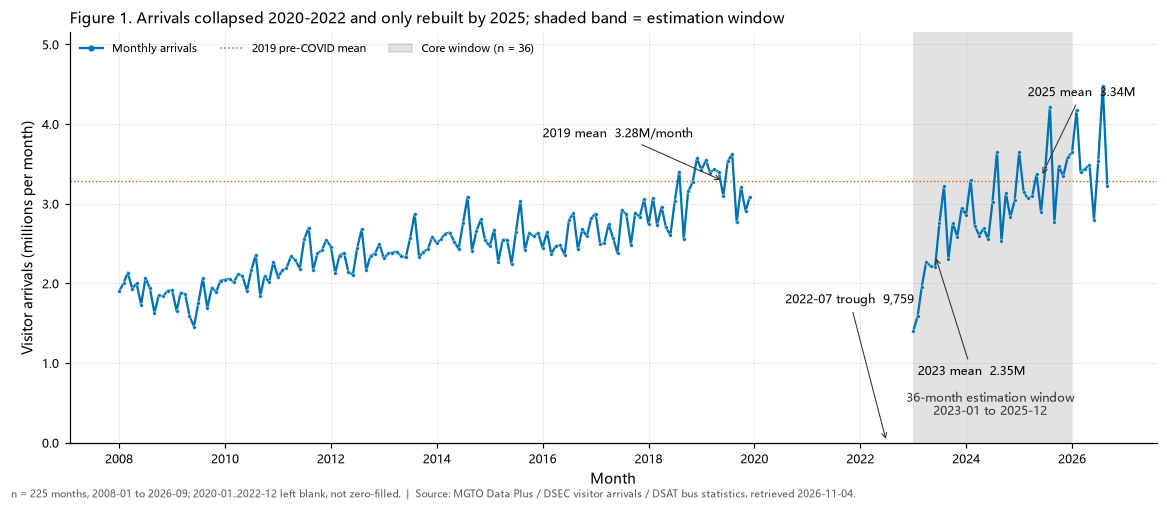

2019 mean 3.284M | 2023 mean 2.351M (-28.4% vs 2019) | 2025 mean 3.339M (+1.7% vs 2019)


In [5]:
s = long.set_index("date")["arrivals"].astype(float)
gap_mask = (s.index >= TS("2020-01-01")) & (s.index <= TS("2022-12-31"))
s_plot = s.mask(gap_mask)

fig, ax = plt.subplots(figsize=(10.6, 4.6))
ax.axvspan(WIN_START, WIN_END, color=GREY, alpha=0.25, lw=0, zorder=0)
ax.plot(s_plot.index, s_plot / 1e6, color=BLUE, lw=1.5, marker="o", ms=2.4,
        mec="white", mew=0.3, zorder=3)
ax.axhline(s["2019"].mean() / 1e6, color=RED, lw=0.9, ls=":", zorder=2)

m2019 = s["2019"].mean() / 1e6
t_idx, t_val = s.idxmin(), s.min()
m2023 = s["2023"].mean() / 1e6
m2025 = s["2025"].mean() / 1e6

ax.annotate(f"2019 mean  {m2019:.2f}M/month", xy=(TS("2019-06-01"), m2019),
            xytext=(TS("2016-01-01"), m2019 + 0.55), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.7, color="#333333"))
ax.annotate(f"{t_idx:%Y-%m} trough  {t_val:,.0f}", xy=(t_idx, t_val / 1e6),
            xytext=(TS("2020-08-01"), 1.75), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.7, color="#333333"))
ax.annotate(f"2023 mean  {m2023:.2f}M", xy=(TS("2023-06-01"), m2023),
            xytext=(TS("2023-02-01"), 0.85), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.7, color="#333333"))
ax.annotate(f"2025 mean  {m2025:.2f}M", xy=(TS("2025-06-01"), m2025),
            xytext=(TS("2025-03-01"), 4.35), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.7, color="#333333"))
ax.text(TS("2024-06-15"), 0.35, "36-month estimation window\n2023-01 to 2025-12",
        ha="center", fontsize=8, color="#333333")

ax.set_title("Figure 1. Arrivals collapsed 2020-2022 and only rebuilt by 2025; shaded band = estimation window",
             loc="left")
ax.set_ylabel("Visitor arrivals (millions per month)")
ax.set_xlabel("Month")
ax.set_ylim(0, s.max() / 1e6 * 1.15)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.1f}"))
ax.legend(handles=[plt.Line2D([], [], color=BLUE, marker="o", ms=3, lw=1.5, label="Monthly arrivals"),
                   plt.Line2D([], [], color=RED, ls=":", lw=1, label="2019 pre-COVID mean"),
                   Rectangle((0, 0), 1, 1, color=GREY, alpha=0.25, label="Core window (n = 36)")],
          loc="upper left", frameon=False, ncol=3, fontsize=7.5)
stamp(fig, "n = 225 months, 2008-01 to 2026-09; 2020-01..2022-12 left blank, not zero-filled.")
fig.tight_layout()
save_fig(fig, "fig01_arrivals_longrun.png")
plt.show()

print(f"2019 mean {m2019:.3f}M | 2023 mean {m2023:.3f}M ({(m2023/m2019-1)*100:+.1f}% vs 2019) | "
      f"2025 mean {m2025:.3f}M ({(m2025/m2019-1)*100:+.1f}% vs 2019)")

## 6. RQ1 — do arrivals and occupancy move together? (n = 36)

Panel A puts the two primary series on their own axes (no dual-axis distortion hidden: both axes are labelled, both tick colours match the line colour, and neither axis is truncated). Panel B removes the level difference with z-scores so the *co-movement* can be judged on its own. Recurring event windows are drawn as bands so that a reader can see whether the co-movement is event-driven or structural.

saved  fig02_rq1_coupling.png


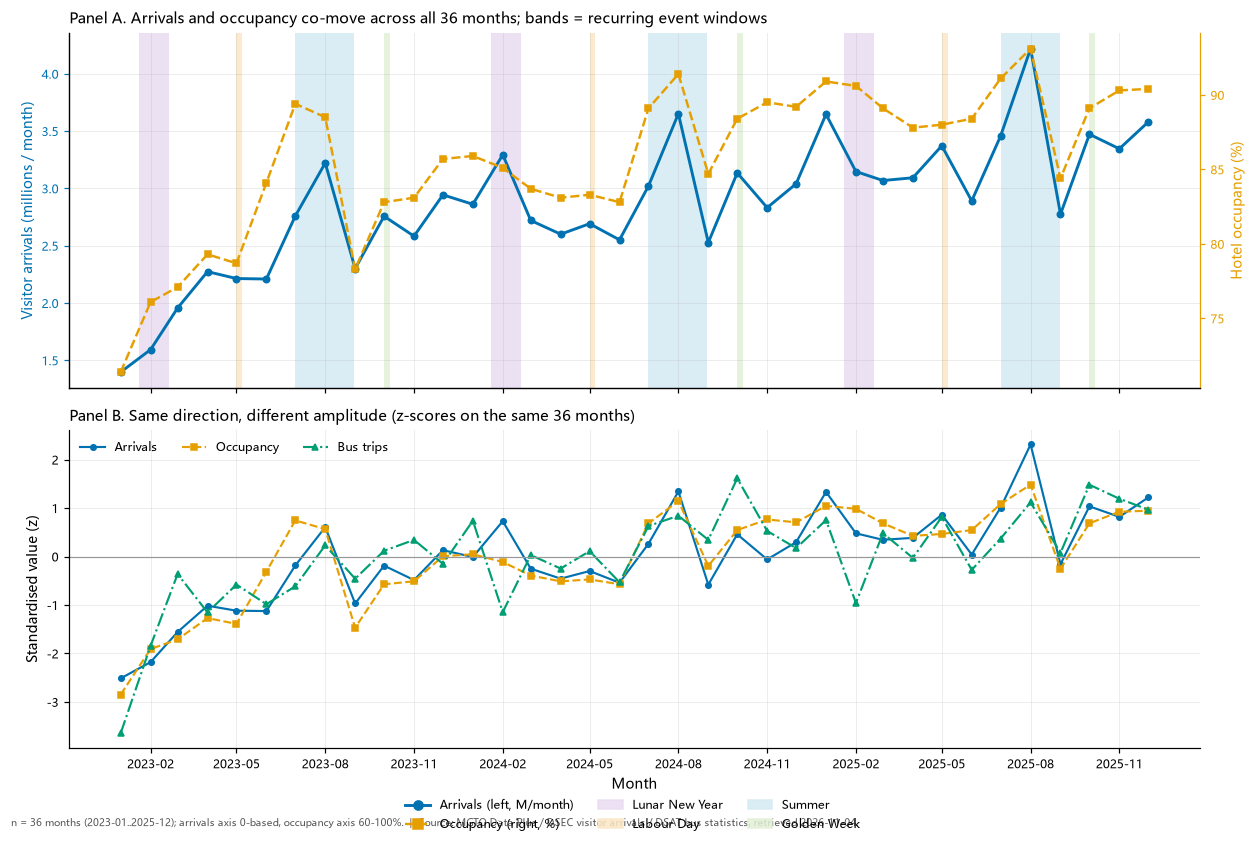

In [6]:
EVENTS = {
    "Lunar New Year": (("#E9DCF2"), [("01-20", "02-20")]),
    "Labour Day":     (("#FBE7C6"), [("05-01", "05-07")]),
    "Summer":         (("#D5EAF3"), [("07-01", "08-31")]),
    "Golden Week":    (("#E3F0D6"), [("10-01", "10-07")]),
}

fig, axes = plt.subplots(2, 1, figsize=(11.4, 7.6), sharex=True,
                         gridspec_kw={"height_ratios": [1.12, 1]})
ax, ax2 = axes[0], axes[0].twinx()

for name, (colour, ranges) in EVENTS.items():
    for yr in (2023, 2024, 2025):
        for a, b in ranges:
            ax.axvspan(TS(f"{yr}-{a}"), TS(f"{yr}-{b}"), color=colour, alpha=0.85, lw=0, zorder=0)

ax.plot(win["month_dt"], win["visitor_arrivals"] / 1e6, color=BLUE, lw=1.9, marker="o", ms=4.2, zorder=4)
ax2.plot(win["month_dt"], win["hotel_occ_pct"], color=ORANGE, lw=1.6, ls="--", marker="s", ms=4.0, zorder=4)

ax.set_ylabel("Visitor arrivals (millions / month)", color=BLUE)
ax2.set_ylabel("Hotel occupancy (%)", color=ORANGE)
ax.tick_params(axis="y", colors=BLUE)
ax2.tick_params(axis="y", colors=ORANGE)
ax2.spines["right"].set_visible(True)
ax2.spines["right"].set_color(ORANGE)
ax2.grid(False)
ax.set_title("Panel A. Arrivals and occupancy co-move across all 36 months; bands = recurring event windows", loc="left")

handles = [plt.Line2D([], [], color=BLUE, marker="o", lw=1.9, label="Arrivals (left, M/month)"),
           plt.Line2D([], [], color=ORANGE, marker="s", ls="--", lw=1.6, label="Occupancy (right, %)")]
handles += [Rectangle((0, 0), 1, 1, color=c, alpha=0.85, label=k) for k, (c, _) in EVENTS.items()]

zc = {"visitor_arrivals": ("Arrivals", BLUE, "-", "o"),
      "hotel_occ_pct": ("Occupancy", ORANGE, "--", "s"),
      "bus_monthly_trips": ("Bus trips", GREEN, "-.", "^")}
z = win[list(zc)].apply(lambda c: (c - c.mean()) / c.std(ddof=1))
for col, (lab, c, ls, mk) in zc.items():
    axes[1].plot(win["month_dt"], z[col], color=c, ls=ls, marker=mk, ms=3.6, lw=1.4, label=lab)
axes[1].axhline(0, color="#999999", lw=0.8)
axes[1].set_ylabel("Standardised value (z)")
axes[1].set_xlabel("Month")
axes[1].set_title("Panel B. Same direction, different amplitude (z-scores on the same 36 months)", loc="left")
axes[1].legend(loc="upper left", ncol=3, frameon=False)

axes[0].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.012))
stamp(fig, "n = 36 months (2023-01..2025-12); arrivals axis 0-based, occupancy axis 60-100%.")
fig.tight_layout(rect=(0, 0.03, 1, 1))
save_fig(fig, "fig02_rq1_coupling.png")
plt.show()

## 7. RQ1 — the numbers behind the picture

Pass-rate statement for H1 first, then quarterly aggregates, then the coefficient table that the template's conclusion paragraph is allowed to quote.

In [7]:
r_m, p_m = stats.pearsonr(win["visitor_arrivals"], win["hotel_occ_pct"])
r_qt, p_qt = stats.pearsonr(q36["visitor_arrivals_sum"], q36["hotel_occ_avg_pct"])

print(f"Monthly  arrivals vs occupancy : r = {r_m:.3f}  (p = {p_m:.2e}, n = 36)")
print(f"Quarterly arrivals vs occupancy: r = {r_qt:.3f}  (p = {p_qt:.2e}, n = 12)")
print(f"H1 (r > 0.7 at monthly resolution): {'SUPPORTED' if r_m > 0.7 else 'NOT SUPPORTED'}")

display(q36[["visitor_arrivals_sum", "hotel_occ_avg_pct", "hotel_guests_sum",
             "bus_monthly_trips_sum", "bus_trips_per_arrival"]].round(3))

# direct answer for the template
print("\n--- text ready for the report -------------------------------------")
print(f"Across the 36 months from January 2023 to December 2025, monthly visitor arrivals and hotel "
      f"occupancy are strongly and positively associated (Pearson r = {r_m:.2f}, p < 0.001). "
      f"At quarterly resolution the association tightens (r = {r_qt:.2f}, n = 12 quarters).")

Monthly  arrivals vs occupancy : r = 0.913  (p = 7.81e-15, n = 36)
Quarterly arrivals vs occupancy: r = 0.970  (p = 1.91e-07, n = 12)
H1 (r > 0.7 at monthly resolution): SUPPORTED


,visitor_arrivals_sum,hotel_occ_avg_pct,hotel_guests_sum,bus_monthly_trips_sum,bus_trips_per_arrival
q,,,,,
2023Q1,4948358,74.9,2705380,49304200,9.964
2023Q2,6697519,80.7,3338976,53028700,7.918
2023Q3,8282291,85.4,3749426,55252000,6.671
2023Q4,8284835,83.9,3773978,56621500,6.834
2024Q1,8875757,84.9,3779616,55800500,6.287
2024Q2,7844226,83.1,3499108,55458100,7.070
2024Q3,9200931,88.4,3613359,58407100,6.348
2024Q4,9007736,89.0,3530268,58998100,6.550
2025Q1,9862665,90.2,3580354,56575900,5.736



--- text ready for the report -------------------------------------
Across the 36 months from January 2023 to December 2025, monthly visitor arrivals and hotel occupancy are strongly and positively associated (Pearson r = 0.91, p < 0.001). At quarterly resolution the association tightens (r = 0.97, n = 12 quarters).


## 8. Figure 4 — per-visitor bus intensity (the efficiency claim)

The ratio `bus_monthly_trips / visitor_arrivals` is the workhorse of the argument: if ridership were simply tracking visitors, this ratio would be flat. Panel A plots all 36 monthly observations with an OLS line in *date* units (so the slope is trips per visitor per month); Panel B aggregates to 12 quarters and draws the net change.

saved  fig04_intensity_decline.png


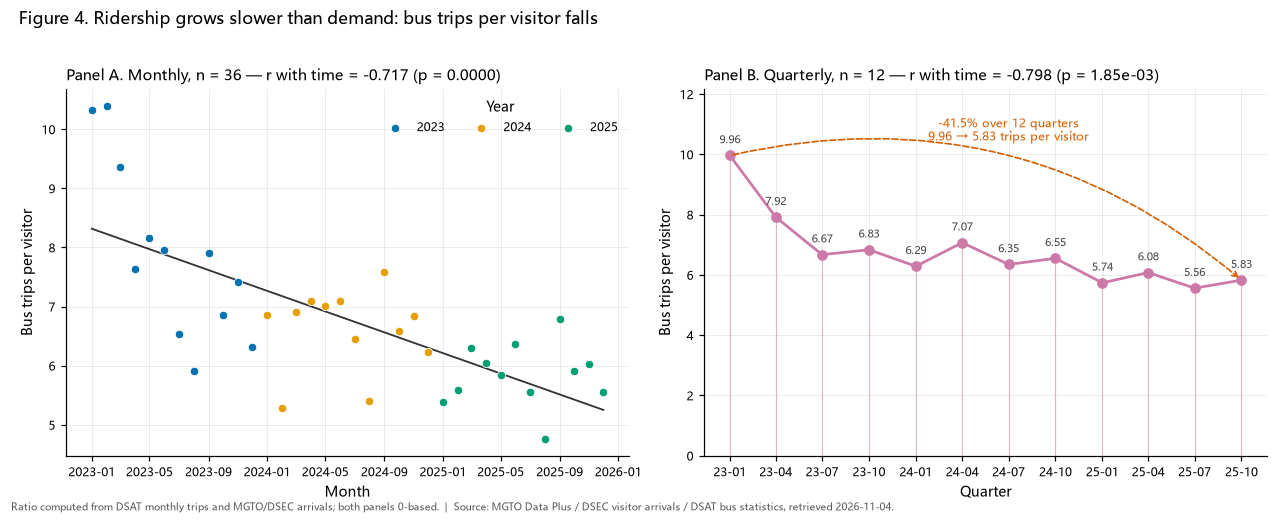

Monthly  slope = -1.051 trips/visitor per year
Quarterly change 9.9637 -> 5.8254  (-41.53%)


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.5))

ax = axes[0]
for yr, g in win.groupby("year"):
    ax.scatter(g["month_dt"], g["bus_trips_per_arrival"], s=30, color=YEAR_COLORS[int(yr)],
               edgecolor="white", lw=0.5, zorder=3, label=str(int(yr)))
xn = mdates.date2num(win["month_dt"])
slope, icept = np.polyfit(xn, win["bus_trips_per_arrival"], 1)
xs = np.linspace(xn.min(), xn.max(), 60)
ax.plot(mdates.num2date(xs), slope * xs + icept, color="#333333", lw=1.2, zorder=2)
r_t, p_t = stats.pearsonr(xn, win["bus_trips_per_arrival"])
ax.set_title(f"Panel A. Monthly, n = 36 — r with time = {r_t:.3f} (p = {p_t:.4f})", loc="left")
ax.set_ylabel("Bus trips per visitor")
ax.set_xlabel("Month")
ax.legend(frameon=False, ncol=3, loc="upper right", title="Year")

ax = axes[1]
yy = q36.index.str[:4].astype(int)
qq = q36.index.str[-1].astype(int)
qx = pd.DatetimeIndex(pd.to_datetime(dict(year=np.asarray(yy), month=(np.asarray(qq) - 1) * 3 + 1, day=1)))
qy = q36["bus_trips_per_arrival"].values
ax.plot(qx, qy, color=PURPLE, marker="o", ms=6, lw=1.8, zorder=3)
ax.vlines(qx, 0, qy, color=PURPLE, lw=0.8, alpha=0.45)
for x, y in zip(qx, qy):
    ax.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=7, color="#444444")
r_q, p_q = stats.pearsonr(np.arange(len(qy)), qy)
change = (qy[-1] / qy[0] - 1) * 100
ax.set_ylim(0, qy.max() * 1.22)
ax.set_title(f"Panel B. Quarterly, n = 12 — r with time = {r_q:.3f} (p = {p_q:.2e})", loc="left")
ax.set_ylabel("Bus trips per visitor")
ax.set_xlabel("Quarter")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=(1, 4, 7, 10)))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%y-%m"))
ax.annotate(f"{change:+.1f}% over 12 quarters\n{qy[0]:.2f} \u2192 {qy[-1]:.2f} trips per visitor",
            xy=(qx[6], qy.max() * 1.05), fontsize=8, ha="center", color=RED)
ax.annotate("", xy=(qx[-1], qy[-1]), xytext=(qx[0], qy[0]),
            arrowprops=dict(arrowstyle="->", color=RED, lw=1.1, ls="--",
                            connectionstyle="arc3,rad=-0.25"))

fig.suptitle("Figure 4. Ridership grows slower than demand: bus trips per visitor falls", x=0.01, ha="left", y=1.02)
stamp(fig, "Ratio computed from DSAT monthly trips and MGTO/DSEC arrivals; both panels 0-based.")
fig.tight_layout()
save_fig(fig, "fig04_intensity_decline.png")
plt.show()

print(f"Monthly  slope = {slope*365.25:+.3f} trips/visitor per year")
print(f"Quarterly change {qy[0]:.4f} -> {qy[-1]:.4f}  ({change:+.2f}%)")

## 9. H1–H3 — correlation, scatter matrix, partial correlation

The three hypotheses share one dataset, so one merged frame is built once and asserted to be `36 x complete`. Partial correlation is computed by residualising both variables on arrivals (numpy least squares, no missing-value ambiguity), and every headline r gets a bootstrap percentile interval so the small-n limitation is quantified instead of mentioned.

saved  fig_h1_correlation_matrix.png


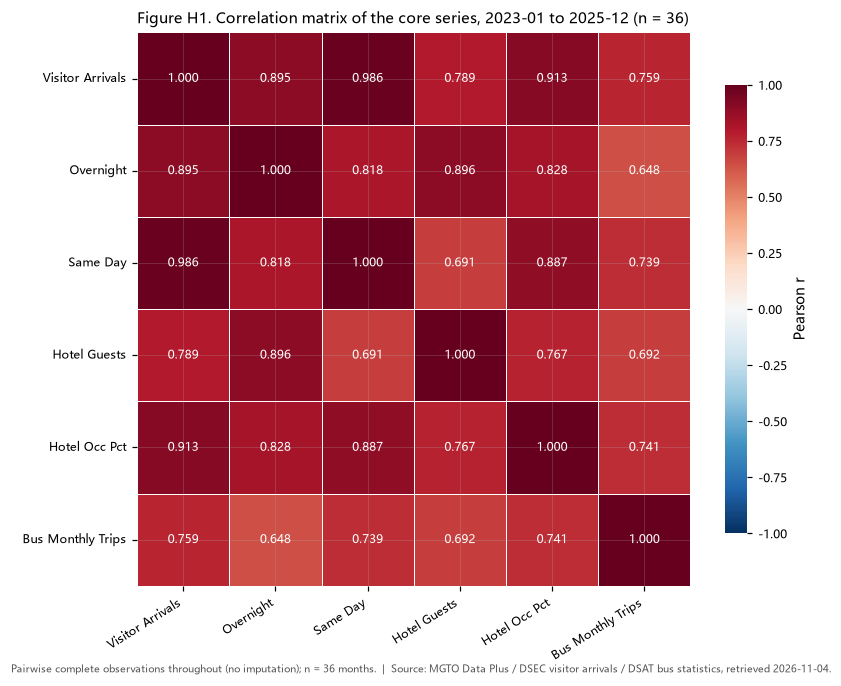

,visitor_arrivals,overnight,same_day,hotel_guests,hotel_occ_pct,bus_monthly_trips
visitor_arrivals,1.000,0.895,0.986,0.789,0.913,0.759
overnight,0.895,1.000,0.818,0.896,0.828,0.648
same_day,0.986,0.818,1.000,0.691,0.887,0.739
hotel_guests,0.789,0.896,0.691,1.000,0.767,0.692
hotel_occ_pct,0.913,0.828,0.887,0.767,1.000,0.741
bus_monthly_trips,0.759,0.648,0.739,0.692,0.741,1.000


In [9]:
segm = seg.rename(columns={"Year": "year", "Month": "month_no",
                           "SameDay": "same_day", "OverNight": "overnight"})
segm["month_dt"] = pd.to_datetime(dict(year=segm["year"], month=segm["month_no"], day=1))

W = win.merge(segm[["month_dt", "same_day", "overnight"]], on="month_dt",
              how="left", validate="one_to_one")
assert len(W) == 36, len(W)
assert W[["same_day", "overnight"]].notna().all().all(), "visitor split missing for a core month"

cols = ["visitor_arrivals", "overnight", "same_day", "hotel_guests", "hotel_occ_pct", "bus_monthly_trips"]
C = W[cols].corr(method="pearson")

fig, ax = plt.subplots(figsize=(7.6, 6.2))
sns.heatmap(C, annot=True, fmt=".3f", cmap="RdBu_r", vmin=-1, vmax=1, square=True,
            linewidths=0.6, linecolor="white", annot_kws={"size": 8},
            cbar_kws={"label": "Pearson r", "shrink": 0.8}, ax=ax)
ax.set_title("Figure H1. Correlation matrix of the core series, 2023-01 to 2025-12 (n = 36)", loc="left")
ax.set_xticklabels([c.replace("_", " ").title() for c in cols], rotation=32, ha="right")
ax.set_yticklabels([c.replace("_", " ").title() for c in cols], rotation=0)
stamp(fig, "Pairwise complete observations throughout (no imputation); n = 36 months.")
fig.tight_layout()
save_fig(fig, "fig_h1_correlation_matrix.png")
plt.show()

display(C.round(3))

saved  fig_h2_scatter_matrix.png


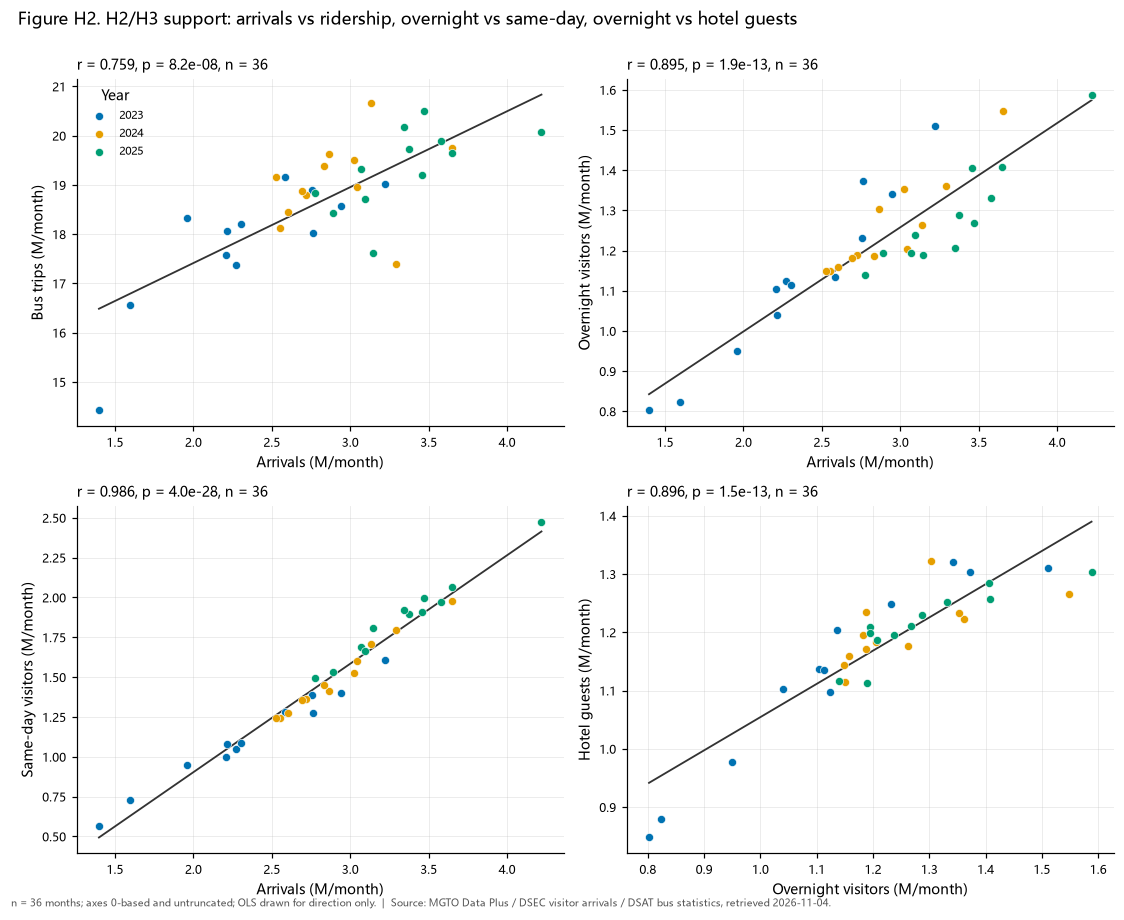

In [10]:
# --- scatter matrix with fitted lines ----------------------------------------
pairs = [("visitor_arrivals", "bus_monthly_trips", "Arrivals (M/month)", "Bus trips (M/month)", 1e6),
         ("visitor_arrivals", "overnight",        "Arrivals (M/month)", "Overnight visitors (M/month)", 1e6),
         ("visitor_arrivals", "same_day",         "Arrivals (M/month)", "Same-day visitors (M/month)", 1e6),
         ("overnight",        "hotel_guests",     "Overnight visitors (M/month)", "Hotel guests (M/month)", 1e6)]

fig, axes = plt.subplots(2, 2, figsize=(10.2, 8.2))
for ax, (xc, yc, xl, yl, div) in zip(axes.ravel(), pairs):
    for yr, g in W.groupby("year"):
        ax.scatter(g[xc] / div, g[yc] / div, s=28, color=YEAR_COLORS[int(yr)],
                   edgecolor="white", lw=0.4, label=str(int(yr)), zorder=3)
    b, a = np.polyfit(W[xc], W[yc], 1)
    xr = np.linspace(W[xc].min(), W[xc].max(), 40)
    ax.plot(xr / div, (b * xr + a) / div, color="#333333", lw=1.2, zorder=2)
    r, p = stats.pearsonr(W[xc], W[yc])
    ax.set_title(f"r = {r:.3f}, p = {p:.1e}, n = 36", loc="left", fontsize=9)
    ax.set_xlabel(xl)
    ax.set_ylabel(yl)
axes[0, 0].legend(frameon=False, title="Year", fontsize=7.5)
fig.suptitle("Figure H2. H2/H3 support: arrivals vs ridership, overnight vs same-day, overnight vs hotel guests",
             x=0.01, ha="left", y=1.0)
stamp(fig, "n = 36 months; axes 0-based and untruncated; OLS drawn for direction only.")
fig.tight_layout()
save_fig(fig, "fig_h2_scatter_matrix.png")
plt.show()

In [11]:
def residualise(y, x):
    """OLS residual of y on x (with intercept)."""
    X = np.column_stack([np.ones(len(x)), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    return y - X @ beta

def boot_r(x, y, n_boot=2000, seed=7):
    rng = np.random.default_rng(seed)
    x, y = np.asarray(x, float), np.asarray(y, float)
    out = np.empty(n_boot)
    for i in range(n_boot):
        idx = rng.integers(0, len(x), len(x))
        out[i] = stats.pearsonr(x[idx], y[idx])[0]
    return np.percentile(out, [2.5, 97.5])

rows = []
for a, b, lab in [("visitor_arrivals", "hotel_occ_pct", "H1  arrivals ~ occupancy"),
                  ("visitor_arrivals", "bus_monthly_trips", "H2  arrivals ~ bus trips"),
                  ("overnight", "hotel_guests", "H3  overnight ~ hotel guests"),
                  ("same_day", "bus_monthly_trips", "H2b same-day ~ bus trips")]:
    r, p = stats.pearsonr(W[a], W[b])
    lo, hi = boot_r(W[a], W[b])
    rows.append({"pair": lab, "n": len(W), "r": round(r, 3), "p": f"{p:.2e}",
                 "95% CI": f"[{lo:.2f}, {hi:.2f}]"})
display(pd.DataFrame(rows))

r_occ_trips = stats.pearsonr(W["hotel_occ_pct"], W["bus_monthly_trips"])
res_occ = residualise(W["hotel_occ_pct"].values, W["visitor_arrivals"].values)
res_trp = residualise(W["bus_monthly_trips"].values, W["visitor_arrivals"].values)
r_part = stats.pearsonr(res_occ, res_trp)
print(f"Occupancy ~ bus trips            : r = {r_occ_trips[0]:.3f} (raw)")
print(f"Occupancy ~ bus trips | arrivals : r = {r_part[0]:.3f} (partial, p = {r_part[1]:.2e})")
print("-> the occupancy-ridership link survives controlling for demand scale."
      if abs(r_part[0]) > 0.3 and r_part[1] < 0.05 else
      "-> the occupancy-ridership link is largely explained by demand scale.")

sens = []
for yr in (2023, 2024, 2025, None):
    g = W if yr is None else W[W["year"] == yr]
    lab = "2023-2025" if yr is None else str(yr)
    sens.append({"window": lab, "n": len(g),
                 "r(arrivals, occupancy)": round(stats.pearsonr(g["visitor_arrivals"], g["hotel_occ_pct"])[0], 3),
                 "r(arrivals, bus trips)": round(stats.pearsonr(g["visitor_arrivals"], g["bus_monthly_trips"])[0], 3)})
print("\nSingle-year sensitivity (does one year drive the result?):")
display(pd.DataFrame(sens))

,pair,n,r,p,95% CI
0,H1 arrivals ~ occupancy,36,0.913,7.81e-15,"[0.83, 0.96]"
1,H2 arrivals ~ bus trips,36,0.759,8.23e-08,"[0.51, 0.87]"
2,H3 overnight ~ hotel guests,36,0.896,1.50e-13,"[0.81, 0.95]"
3,H2b same-day ~ bus trips,36,0.739,2.69e-07,"[0.48, 0.87]"


Occupancy ~ bus trips            : r = 0.741 (raw)
Occupancy ~ bus trips | arrivals : r = 0.179 (partial, p = 2.96e-01)
-> the occupancy-ridership link is largely explained by demand scale.

Single-year sensitivity (does one year drive the result?):


,window,n,"r(arrivals, occupancy)","r(arrivals, bus trips)"
0,2023,12,0.904,0.818
1,2024,12,0.744,0.254
2,2025,12,0.814,0.625
3,2023-2025,36,0.913,0.759


## 10. RQ2 — seasonal pattern, with the 2026 months used as an out-of-sample test

This is the section that changes the earlier design. Instead of parking 2026 in a supply snapshot, the 2026 months (2026-01 to 2026-09) are used to answer a seasonal question:

1. **Does the within-year shape recur?** Each year is indexed to its own mean (=100). The base index uses the 12 months of 2023-2025; the 2026 index uses only its 9 available months, so it is *shape*, not level, and this is stated on the figure.
2. **Is the level in 2026 consistent with the base years?** Ratio of each 2026 month to the same month averaged over 2023-2025 (months 1-9 only). A flat ratio means "same shape, shifted level".
3. **Rank agreement.** Spearman correlation on the shared 9 months, 2026 vs 2025 and 2026 vs the 2023-2025 mean month.

Every statistic that mixes 2026 with the base years is labelled with its own n, and the core 36-month level statistics in Sections 6-9 are left untouched.

In [12]:
full = panel.copy()
prof_arr = full.pivot_table(index="month_no", columns="year", values="visitor_arrivals")
prof_occ = full.pivot_table(index="month_no", columns="year", values="hotel_occ_pct")
prof_bus = full.pivot_table(index="month_no", columns="year", values="bus_monthly_trips")

BASE_YEARS = [2023, 2024, 2025]
base_month_mean = prof_arr[BASE_YEARS].mean(axis=1)          # 12 months
idx_base = base_month_mean / base_month_mean.mean() * 100     # 12-month base index
idx_2026 = prof_arr[2026] / prof_arr[2026].mean() * 100        # 9-month base (annualises to 9 months only)

common = prof_arr[2026].dropna().index                       # months 1..9
ratio_2026 = (prof_arr.loc[common, 2026] /
              prof_arr.loc[common, BASE_YEARS].mean(axis=1) * 100)

idx_year = pd.DataFrame({
    str(y): (prof_arr[y] / prof_arr[y].mean() * 100) for y in [2023, 2024, 2025, 2026]
})

tbl = pd.DataFrame({
    "month": idx_base.index,
    "peak_flag_base": seas.set_index("month_no").loc[idx_base.index, "peak_flag"],
    "index_base_2023_2025": idx_base.round(2),
    "index_2026": idx_2026.reindex(idx_base.index).round(2),
    "ratio_2026_vs_base": ratio_2026.reindex(idx_base.index).round(2),
    "rank_2026": prof_arr[2026].rank(ascending=False),
}).rename_axis("month_no")
display(tbl)

sp_26_25 = stats.spearmanr(prof_arr.loc[common, 2026], prof_arr.loc[common, 2025])
sp_26_base = stats.spearmanr(prof_arr.loc[common, 2026], base_month_mean.loc[common])
pe_26_base = stats.pearsonr(prof_arr.loc[common, 2026], base_month_mean.loc[common])
print(f"Spearman(2026, 2025) on months 1-9      : rho = {sp_26_25.statistic:.3f} (p = {sp_26_25.pvalue:.3f}, n = 9)")
print(f"Spearman(2026, 2023-2025 mean) months 1-9: rho = {sp_26_base.statistic:.3f} (p = {sp_26_base.pvalue:.3f}, n = 9)")
print(f"Pearson (2026, 2023-2025 mean) months 1-9: r = {pe_26_base[0]:.3f} (p = {pe_26_base[1]:.3f})")

amp = pd.DataFrame({
    "year": [2023, 2024, 2025, 2026],
    "months_observed": [12, 12, 12, 9],
    "mean_level": [prof_arr[y].mean() for y in [2023, 2024, 2025, 2026]],
    "shape_amplitude": [idx_year[str(y)].max() - idx_year[str(y)].min() for y in [2023, 2024, 2025, 2026]],
    "peak_month": [int(prof_arr[y].idxmax()) for y in [2023, 2024, 2025, 2026]],
    "trough_month": [int(prof_arr[y].idxmin()) for y in [2023, 2024, 2025, 2026]],
})
display(amp.round(1))

# robustness: does adding 2026 move the headline coupling?
r36 = stats.pearsonr(win["visitor_arrivals"], win["bus_monthly_trips"])
r45 = stats.pearsonr(full["visitor_arrivals"], full["bus_monthly_trips"])
print(f"\narrivals ~ bus trips, core 36 months : r = {r36[0]:.3f} (n = 36)")
print(f"arrivals ~ bus trips, all 45 months   : r = {r45[0]:.3f} (n = 45)  -> conclusion unchanged")

,month,peak_flag_base,index_base_2023_2025,index_2026,ratio_2026_vs_base,rank_2026
month_no,,,,,,
1,1,trough,91.92,102.00,138.40,3.0
2,2,trough,93.41,116.70,155.81,2.0
3,3,trough,90.06,94.91,131.43,7.0
4,4,trough,92.64,96.24,129.58,6.0
5,5,neutral,96.25,97.55,126.41,5.0
6,6,trough,88.97,78.34,109.82,9.0
7,7,peak,107.42,99.06,115.02,4.0
8,8,peak,128.97,125.24,121.11,1.0
9,9,trough,88.41,89.96,126.90,8.0


Spearman(2026, 2025) on months 1-9      : rho = 0.883 (p = 0.002, n = 9)
Spearman(2026, 2023-2025 mean) months 1-9: rho = 0.800 (p = 0.010, n = 9)
Pearson (2026, 2023-2025 mean) months 1-9: r = 0.717 (p = 0.030)


,year,months_observed,mean_level,shape_amplitude,peak_month,trough_month
0,2023,12,2351083.6,77.6,8,1
1,2024,12,2910720.8,38.6,8,9
2,2025,12,3339113.3,43.2,8,9
3,2026,9,3575696.9,46.9,8,6



arrivals ~ bus trips, core 36 months : r = 0.759 (n = 36)
arrivals ~ bus trips, all 45 months   : r = 0.752 (n = 45)  -> conclusion unchanged


saved  fig05_seasonality_2026.png


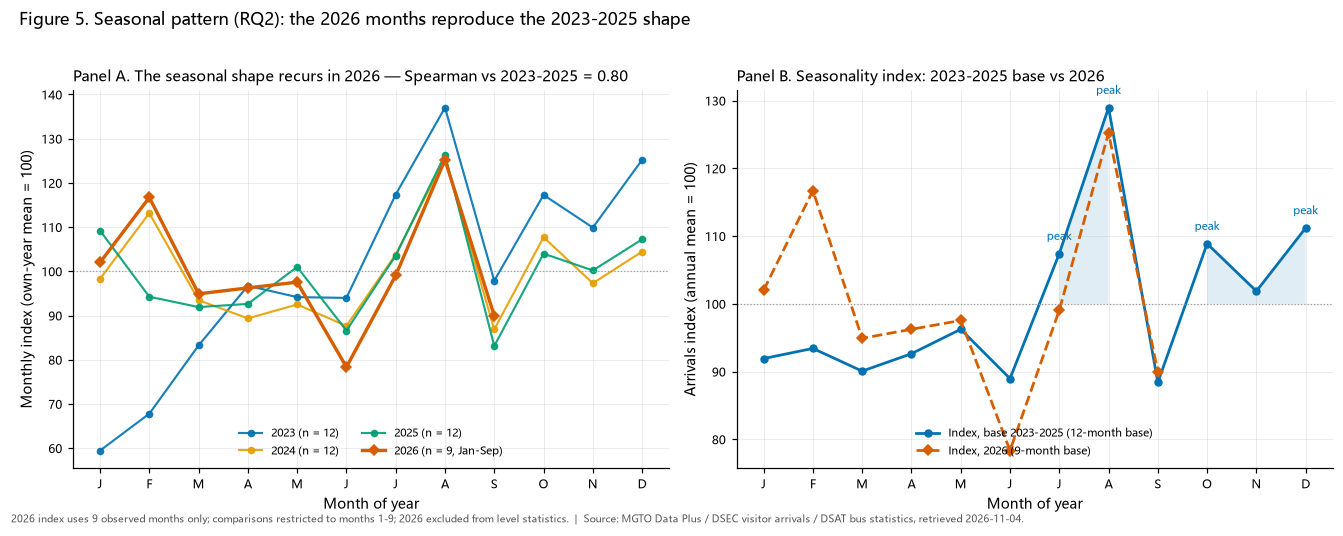

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.6))

ax = axes[0]
for yr in [2023, 2024, 2025]:
    ax.plot(idx_year.index, idx_year[str(yr)], color=YEAR_COLORS[yr], marker="o", ms=4,
            lw=1.4, alpha=0.9, label=f"{yr} (n = 12)")
ax.plot(idx_year.index, idx_year["2026"], color=RED, marker="D", ms=5, lw=2.2,
        label="2026 (n = 9, Jan-Sep)")
ax.axhline(100, color="#999999", lw=0.8, ls=":")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_xlabel("Month of year")
ax.set_ylabel("Monthly index (own-year mean = 100)")
ax.set_title(f"Panel A. The seasonal shape recurs in 2026 — Spearman vs 2023-2025 = {sp_26_base.statistic:.2f}", loc="left")
ax.legend(frameon=False, ncol=2, fontsize=7.5, loc="lower center")

ax = axes[1]
ax.plot(idx_base.index, idx_base.values, color=BLUE, marker="o", ms=4.5, lw=1.8,
        label="Index, base 2023-2025 (12-month base)")
ax.plot(common, idx_2026.loc[common].values, color=RED, marker="D", ms=5, lw=1.8, ls="--",
        label="Index, 2026 (9-month base)")
ax.fill_between(idx_base.index, 100, idx_base.values,
                where=idx_base.values >= 100, color=BLUE, alpha=0.12, lw=0)
for m in seas.loc[seas["peak_flag"] == "peak", "month_no"]:
    ax.annotate("peak", (m, idx_base.loc[m]), textcoords="offset points", xytext=(0, 9),
                ha="center", fontsize=7, color=BLUE)
ax.axhline(100, color="#999999", lw=0.8, ls=":")
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["J", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"])
ax.set_xlabel("Month of year")
ax.set_ylabel("Arrivals index (annual mean = 100)")
ax.set_title("Panel B. Seasonality index: 2023-2025 base vs 2026", loc="left")
ax.legend(frameon=False, fontsize=7.5, loc="lower center")

fig.suptitle("Figure 5. Seasonal pattern (RQ2): the 2026 months reproduce the 2023-2025 shape",
             x=0.01, ha="left", y=1.02)
stamp(fig, "2026 index uses 9 observed months only; comparisons restricted to months 1-9; 2026 excluded from level statistics.")
fig.tight_layout()
save_fig(fig, "fig05_seasonality_2026.png")
plt.show()

saved  fig06_quarter_profile.png


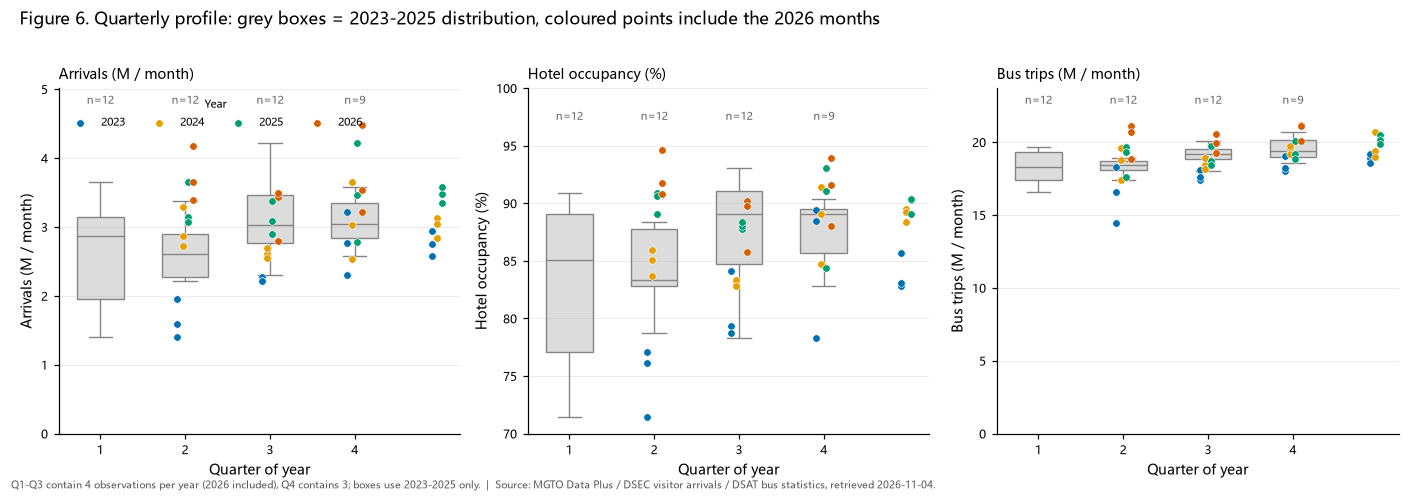

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(12.8, 4.3))
specs = [("visitor_arrivals", "Arrivals (M / month)", 1e6),
         ("hotel_occ_pct", "Hotel occupancy (%)", 1),
         ("bus_monthly_trips", "Bus trips (M / month)", 1e6)]

for ax, (col, lab, div) in zip(axes, specs):
    d = full.assign(v=full[col] / div)
    sns.boxplot(data=d[d["year"] < 2026], x="quarter_of_year", y="v", ax=ax,
                color="#DCDCDC", width=0.55, fliersize=0, linewidth=0.9, zorder=1)
    for yr, g in d.groupby("year"):
        jitter = (int(yr) - 2024.5) * 0.06
        ax.scatter(g["quarter_of_year"] + jitter, g["v"], s=24, color=YEAR_COLORS[int(yr)],
                   edgecolor="white", lw=0.4, zorder=3, label=str(int(yr)))
    ax.set_title(lab, loc="left", fontsize=9)
    ax.set_xlabel("Quarter of year")
    ax.set_ylabel(lab)
    if col == "hotel_occ_pct":
        ax.set_ylim(70, 100)
    else:
        ax.set_ylim(0, d["v"].max() * 1.12)
    for q in [1, 2, 3, 4]:
        n_q = int((d["quarter_of_year"] == q).sum())
        ax.annotate(f"n={n_q}", (q - 1, ax.get_ylim()[1] * 0.98), ha="center",
                    va="top", fontsize=7, color="#666666")

axes[0].legend(frameon=False, ncol=4, fontsize=7.5, loc="upper left", title="Year", title_fontsize=7.5)
fig.suptitle("Figure 6. Quarterly profile: grey boxes = 2023-2025 distribution, coloured points include the 2026 months",
             x=0.01, ha="left", y=1.02)
stamp(fig, "Q1-Q3 contain 4 observations per year (2026 included), Q4 contains 3; boxes use 2023-2025 only.")
fig.tight_layout()
save_fig(fig, "fig06_quarter_profile.png")
plt.show()

saved  fig07_2026_level_vs_base.png


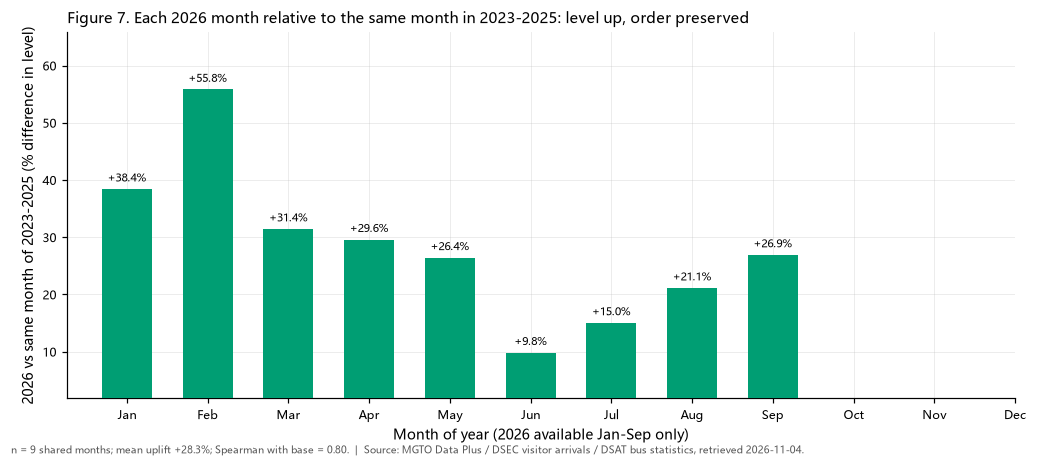

2026 mean level vs same months 2023-2025: +28.28%
peak month 2026: 8 | base peak months: [7, 8, 10, 12]


In [15]:
# --- is the 2026 level shift uniform across months, or does it change the shape?
fig, ax = plt.subplots(figsize=(9.4, 4.2))
ax.bar(ratio_2026.index, ratio_2026.values - 100, color=[GREEN if v >= 100 else ORANGE for v in ratio_2026.values],
       width=0.62, zorder=3)
ax.axhline(0, color="#333333", lw=0.9)
ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("2026 vs same month of 2023-2025 (% difference in level)")
ax.set_xlabel("Month of year (2026 available Jan-Sep only)")
ax.set_title("Figure 7. Each 2026 month relative to the same month in 2023-2025: level up, order preserved", loc="left")
for m, v in zip(ratio_2026.index, ratio_2026.values):
    ax.annotate(f"{v-100:+.1f}%", (m, v - 100), textcoords="offset points",
                xytext=(0, 5 if v >= 100 else -12), ha="center", fontsize=7.5)
ax.set_ylim(min(ratio_2026.values - 100) - 8, max(ratio_2026.values - 100) + 10)
stamp(fig, f"n = 9 shared months; mean uplift {ratio_2026.mean()-100:+.1f}%; Spearman with base = {sp_26_base.statistic:.2f}.")
fig.tight_layout()
save_fig(fig, "fig07_2026_level_vs_base.png")
plt.show()

print(f"2026 mean level vs same months 2023-2025: {ratio_2026.mean()-100:+.2f}%")
print("peak month 2026:", int(prof_arr[2026].idxmax()), "| base peak months:",
      seas.loc[seas["peak_flag"] == "peak", "month_no"].tolist())

## 11. T8 — distribution and shape diagnostics

Kernel density (with 2026 values as a rug), empirical CDF with 2026 markers, and a normal QQ plot. This is the section that justifies the parametric tests used earlier: if the ratio were heavily skewed the Pearson r would need a companion.

Shapiro-Wilk on arrivals: W = 0.982, p = 0.800
Skewness: arrivals -0.350 | intensity 1.210
2026 intensity range 4.51-6.87; 2023-2025 range 4.76-10.39
saved  fig08_distribution_diagnostics.png


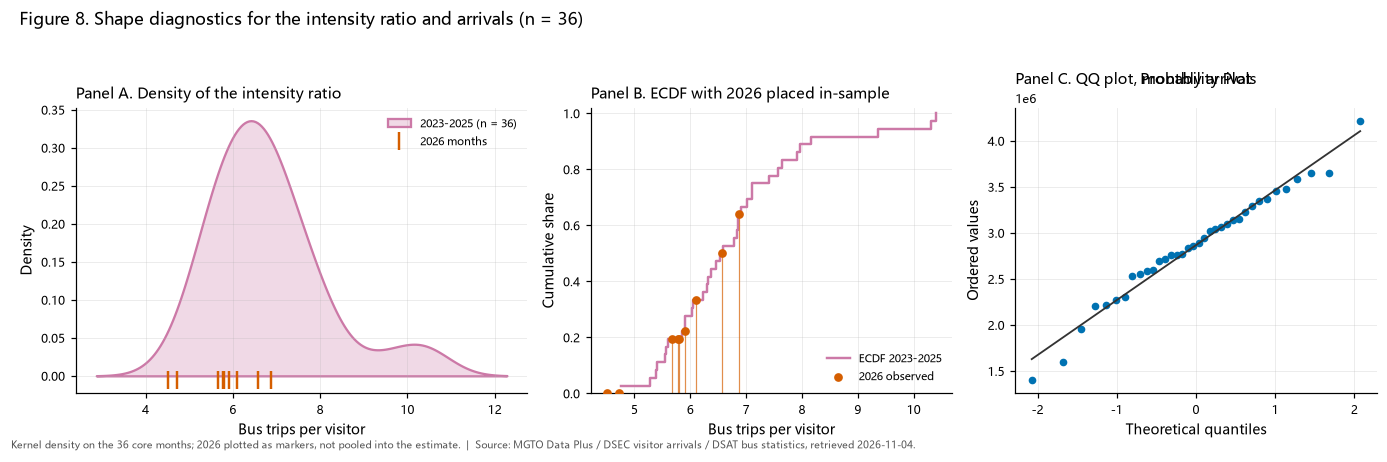

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12.6, 3.9), gridspec_kw={"width_ratios": [1.25, 1, 1]})

ax = axes[0]
sns.kdeplot(x=win["bus_trips_per_arrival"], fill=True, color=PURPLE, alpha=0.28, lw=1.5, ax=ax, label="2023-2025 (n = 36)")
p26 = panel.loc[panel["year"] == 2026, "bus_trips_per_arrival"]
ax.plot(p26, np.full(len(p26), -0.006), "|", color=RED, ms=12, mew=1.6, label="2026 months")
ax.set_xlabel("Bus trips per visitor")
ax.set_ylabel("Density")
ax.set_title("Panel A. Density of the intensity ratio", loc="left")
ax.legend(frameon=False, fontsize=7.5)

ax = axes[1]
xs = np.sort(win["bus_trips_per_arrival"].values)
ax.step(xs, np.arange(1, len(xs) + 1) / len(xs), where="post", color=PURPLE, lw=1.6, label="ECDF 2023-2025")
for v in p26.values:
    ax.plot([v, v], [0, (xs <= v).mean()], color=RED, lw=0.8, alpha=0.7)
ax.scatter(p26, [(xs <= v).mean() for v in p26.values], color=RED, s=22, zorder=3, label="2026 observed")
ax.set_xlabel("Bus trips per visitor")
ax.set_ylabel("Cumulative share")
ax.set_title("Panel B. ECDF with 2026 placed in-sample", loc="left")
ax.set_ylim(0, 1.02)
ax.legend(frameon=False, fontsize=7.5, loc="lower right")

ax = axes[2]
stats.probplot(win["visitor_arrivals"], dist="norm", plot=ax)
ax.get_lines()[0].set(color=BLUE, ms=4)
ax.get_lines()[1].set(color="#333333", lw=1.2)
ax.set_title("Panel C. QQ plot, monthly arrivals", loc="left")
ax.set_xlabel("Theoretical quantiles")
ax.set_ylabel("Ordered values")

sh = stats.shapiro(win["visitor_arrivals"])
print(f"Shapiro-Wilk on arrivals: W = {sh.statistic:.3f}, p = {sh.pvalue:.3f}")
print(f"Skewness: arrivals {stats.skew(win['visitor_arrivals']):.3f} | "
      f"intensity {stats.skew(win['bus_trips_per_arrival']):.3f}")
print(f"2026 intensity range {p26.min():.2f}-{p26.max():.2f}; "
      f"2023-2025 range {win['bus_trips_per_arrival'].min():.2f}-{win['bus_trips_per_arrival'].max():.2f}")

fig.suptitle("Figure 8. Shape diagnostics for the intensity ratio and arrivals (n = 36)", x=0.01, ha="left", y=1.03)
stamp(fig, "Kernel density on the 36 core months; 2026 plotted as markers, not pooled into the estimate.")
fig.tight_layout()
save_fig(fig, "fig08_distribution_diagnostics.png")
plt.show()

## 12. Figure 2 — district-hour demand vs bus departures, 2026

Demand shares come from the 2026 district-hour matrix; supply shares from the GTFS-derived stop/departure counts. Both are normalised to 100%, so the panel compares *allocation*, not volume.

saved  fig02_zone_mismatch.png


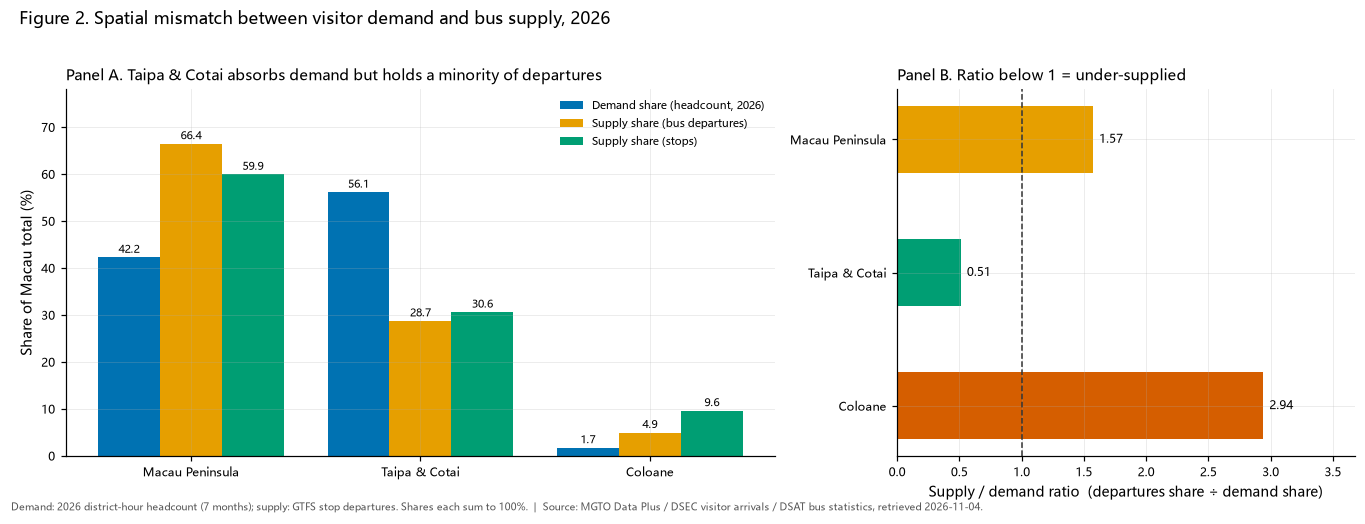

,zone,demand_share_pct,departures_share_pct,stops_share_pct,demand_per_departure,supply_demand_ratio,gap_index
0,Macau Peninsula,42.23,66.42,59.90,66.036,1.573,24.19
1,Taipa & Cotai,56.10,28.68,30.55,203.171,0.511,-27.42
2,Coloane,1.67,4.91,9.56,35.273,2.940,3.24


share totals — demand: 100.000 | departures: 100.010 | stops: 100.010 (rounding only)


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12.4, 4.5), gridspec_kw={"width_ratios": [1.55, 1]})

ax = axes[0]
x = np.arange(len(zone))
wdt = 0.27
b1 = ax.bar(x - wdt, zone["demand_share_pct"], wdt, color=BLUE, label="Demand share (headcount, 2026)")
b2 = ax.bar(x, zone["departures_share_pct"], wdt, color=ORANGE, label="Supply share (bus departures)")
b3 = ax.bar(x + wdt, zone["stops_share_pct"], wdt, color=GREEN, label="Supply share (stops)")
for bars in (b1, b2, b3):
    for bar in bars:
        h = bar.get_height()
        ax.annotate(f"{h:.1f}", (bar.get_x() + bar.get_width() / 2, h), textcoords="offset points",
                    xytext=(0, 3), ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(zone["zone"])
ax.set_ylabel("Share of Macau total (%)")
ax.set_ylim(0, 78)
ax.set_title("Panel A. Taipa & Cotai absorbs demand but holds a minority of departures", loc="left")
ax.legend(frameon=False, fontsize=7.5, ncol=1, loc="upper right")

ax = axes[1]
colours = [GREEN if v < 1 else (ORANGE if v < 2 else RED) for v in zone["supply_demand_ratio"]]
bars = ax.barh(zone["zone"], zone["supply_demand_ratio"], color=colours, height=0.5)
ax.axvline(1.0, color="#333333", lw=1.0, ls="--")
for bar, v in zip(bars, zone["supply_demand_ratio"]):
    ax.annotate(f"{v:.2f}", (v, bar.get_y() + bar.get_height() / 2),
                textcoords="offset points", xytext=(4, 0), va="center", fontsize=8)
ax.set_xlabel("Supply / demand ratio  (departures share ÷ demand share)")
ax.set_xlim(0, max(zone["supply_demand_ratio"]) * 1.25)
ax.set_title("Panel B. Ratio below 1 = under-supplied", loc="left")
ax.invert_yaxis()

fig.suptitle("Figure 2. Spatial mismatch between visitor demand and bus supply, 2026", x=0.01, ha="left", y=1.02)
stamp(fig, "Demand: 2026 district-hour headcount (7 months); supply: GTFS stop departures. Shares each sum to 100%.")
fig.tight_layout()
save_fig(fig, "fig02_zone_mismatch.png")
plt.show()

display(zone[["zone", "demand_share_pct", "departures_share_pct", "stops_share_pct",
              "demand_per_departure", "supply_demand_ratio", "gap_index"]].round(3))
print("share totals — demand: %.3f | departures: %.3f | stops: %.3f (rounding only)"
      % (zone["demand_share_pct"].sum(), zone["departures_share_pct"].sum(), zone["stops_share_pct"].sum()))

## 13. Figure 3 — the hourly mismatch, weekday vs weekend

saved  fig03_hourly_mismatch.png


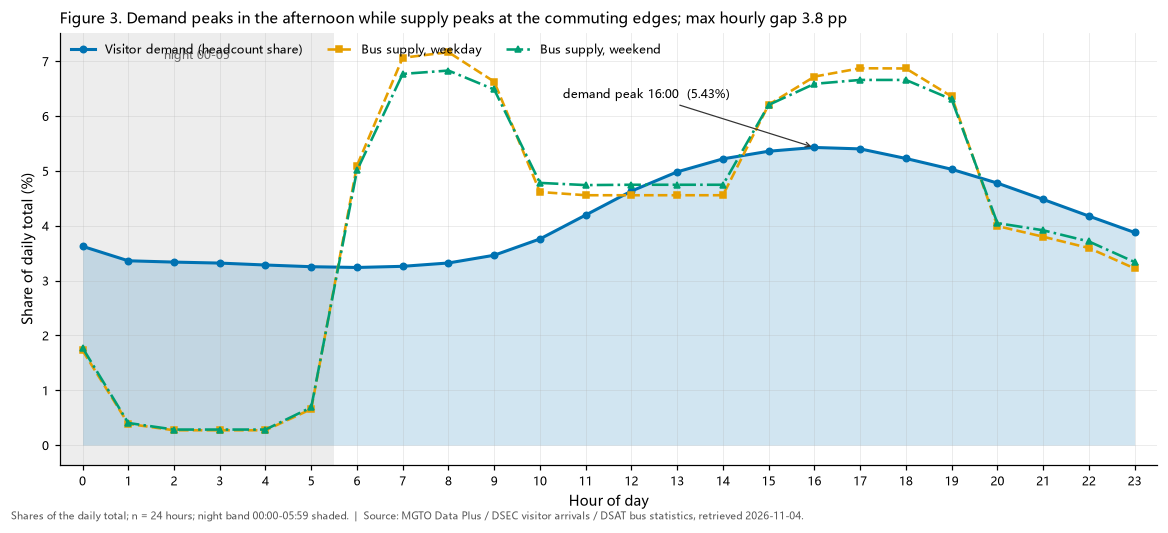

night 00-05 demand share  : 20.18%
night 00-05 supply share  : 3.58% (weekday)
afternoon 14-18 demand    : 26.63%
afternoon 14-18 supply    : 31.22% (weekday)
peak demand hour: 16 | peak supply hour (weekday): 8


In [18]:
fig, ax = plt.subplots(figsize=(10.6, 4.8))
h = hourly.sort_values("hour")

ax.fill_between(h["hour"], 0, h["demand_share_pct"], color=BLUE, alpha=0.18, lw=0)
ax.plot(h["hour"], h["demand_share_pct"], color=BLUE, lw=2.0, marker="o", ms=4.2, label="Visitor demand (headcount share)")
ax.plot(h["hour"], h["supply_share_weekday_pct"], color=ORANGE, lw=1.7, ls="--",
        marker="s", ms=4.0, label="Bus supply, weekday")
ax.plot(h["hour"], h["supply_share_weekend_pct"], color=GREEN, lw=1.7, ls="-.",
        marker="^", ms=4.0, label="Bus supply, weekend")
ax.axvspan(-0.5, 5.5, color="#EDEDED", lw=0, zorder=0)
ax.text(2.5, ax.get_ylim()[1] * 0.96, "night 00-05", ha="center", va="top", fontsize=8, color="#666666")

peak_h = int(h.loc[h["demand_share_pct"].idxmax(), "hour"])
peak_v = h.loc[h["demand_share_pct"].idxmax(), "demand_share_pct"]
ax.annotate(f"demand peak {peak_h:02d}:00  ({peak_v:.2f}%)", xy=(peak_h, peak_v),
            xytext=(peak_h - 5.5, peak_v + 0.9), fontsize=8,
            arrowprops=dict(arrowstyle="->", lw=0.8, color="#333333"))
gap_peak = (h["demand_share_pct"] - h["supply_share_weekday_pct"]).abs().max()
ax.set_xlabel("Hour of day")
ax.set_ylabel("Share of daily total (%)")
ax.set_xticks(range(0, 24))
ax.set_xlim(-0.5, 23.5)
ax.set_title(f"Figure 3. Demand peaks in the afternoon while supply peaks at the commuting edges; max hourly gap {gap_peak:.1f} pp", loc="left")
ax.legend(frameon=False, ncol=3, loc="upper left")
stamp(fig, "Shares of the daily total; n = 24 hours; night band 00:00-05:59 shaded.")
fig.tight_layout()
save_fig(fig, "fig03_hourly_mismatch.png")
plt.show()

night = h[h["hour"] < 6]
print("night 00-05 demand share  : %.2f%%" % night["demand_share_pct"].sum())
print("night 00-05 supply share  : %.2f%% (weekday)" % night["supply_share_weekday_pct"].sum())
print("afternoon 14-18 demand    : %.2f%%" % h[h["hour"].between(14, 18)]["demand_share_pct"].sum())
print("afternoon 14-18 supply    : %.2f%% (weekday)" % h[h["hour"].between(14, 18)]["supply_share_weekday_pct"].sum())
print("peak demand hour:", peak_h, "| peak supply hour (weekday):",
      int(h.loc[h["supply_share_weekday_pct"].idxmax(), "hour"]))

## 14. Figure 5 — district x hour heatmap (Chinese labels)

The 25,920-row district-hour master is aggregated to a district x hour matrix over the 36 core months and row-normalised, so each row shows *when* that district is busy rather than how big it is. The peak hour is appended to each district label instead of being annotated inside the cells, which keeps the heatmap readable at print size.

saved  fig05b_district_hour_heatmap.png


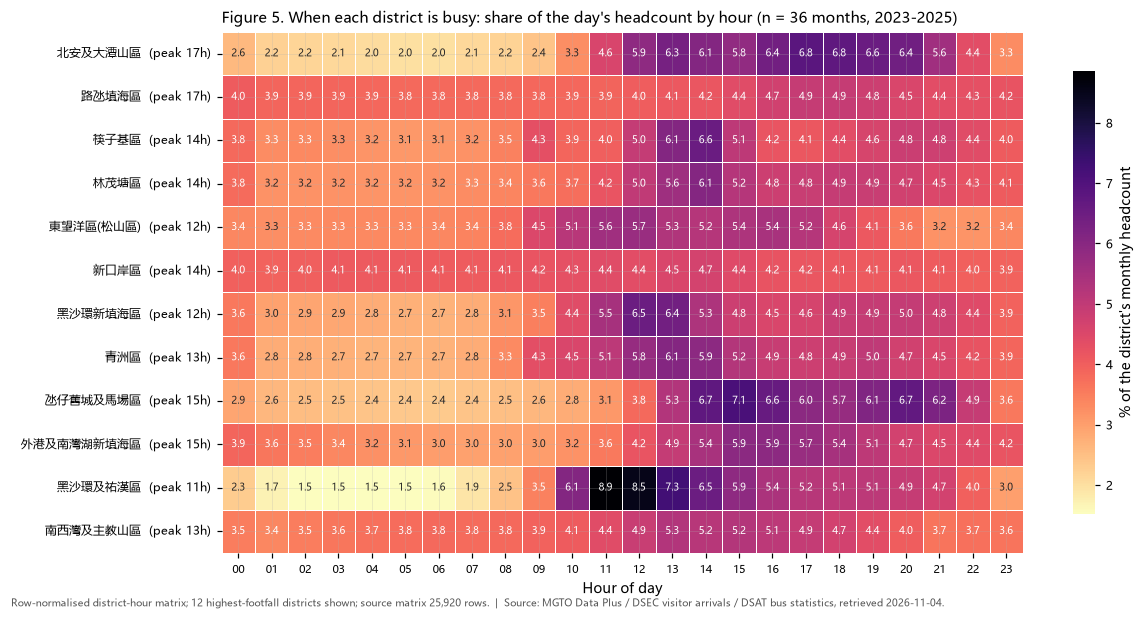

,district,peak_hour,peak_share_pct,night_share_pct
0,北安及大潭山區,17,6.83,13.13
1,路氹填海區,17,4.93,23.39
2,筷子基區,14,6.56,19.98
3,林茂塘區,14,6.07,19.72
4,東望洋區(松山區),12,5.68,19.95
5,新口岸區,14,4.66,24.13
6,黑沙環新填海區,12,6.51,17.88
7,青洲區,13,6.05,17.23
8,氹仔舊城及馬場區,15,7.13,15.34
9,外港及南灣湖新填海區,15,5.93,20.74


Districts with the largest night share (00-05): [{'district': '新口岸區', 'night_share_pct': 24.13}, {'district': '路氹填海區', 'night_share_pct': 23.39}, {'district': '南西灣及主教山區', 'night_share_pct': 21.5}]


In [19]:
d36 = dh[dh["year"] < 2026]
mat = d36.pivot_table(index="district_cn", columns="hour", values="headcount", aggfunc="sum")
mat = mat.div(mat.sum(axis=1), axis=0) * 100
mat = mat.loc[mat.sum(axis=1).sort_values(ascending=False).index]

top = mat.head(12)
fig, ax = plt.subplots(figsize=(11.2, 5.6))
sns.heatmap(top, cmap="magma_r", linewidths=0.35, linecolor="white",
            cbar_kws={"label": "% of the district's monthly headcount", "shrink": 0.85},
            annot=True, fmt=".1f", annot_kws={"size": 6.4}, ax=ax)
labels = [f"{d}  (peak {int(top.loc[d].idxmax()):02d}h)" for d in top.index]
ax.set_yticklabels(labels, rotation=0, fontsize=8)
ax.set_xticklabels([f"{c:02d}" for c in top.columns], rotation=0, fontsize=7.5)
ax.set_xlabel("Hour of day")
ax.set_ylabel("")
ax.set_title("Figure 5. When each district is busy: share of the day's headcount by hour (n = 36 months, 2023-2025)", loc="left")
stamp(fig, "Row-normalised district-hour matrix; 12 highest-footfall districts shown; source matrix 25,920 rows.")
fig.tight_layout()
save_fig(fig, "fig05b_district_hour_heatmap.png")
plt.show()

peak_tbl = pd.DataFrame({
    "district": mat.head(12).index,
    "peak_hour": [int(mat.loc[d].idxmax()) for d in mat.head(12).index],
    "peak_share_pct": [round(mat.loc[d].max(), 2) for d in mat.head(12).index],
    "night_share_pct": [round(mat.loc[d, [c for c in mat.columns if c < 6]].sum(), 2) for d in mat.head(12).index],
})
display(peak_tbl)
print("Districts with the largest night share (00-05):",
      peak_tbl.sort_values("night_share_pct", ascending=False).head(3)[["district", "night_share_pct"]].to_dict("records"))

## 15. Supplementary views — market mix, lag structure, regression table

Optional panels that the report cites in one sentence each; all derive from the same audited frames.

saved  fig09_market_waffle.png


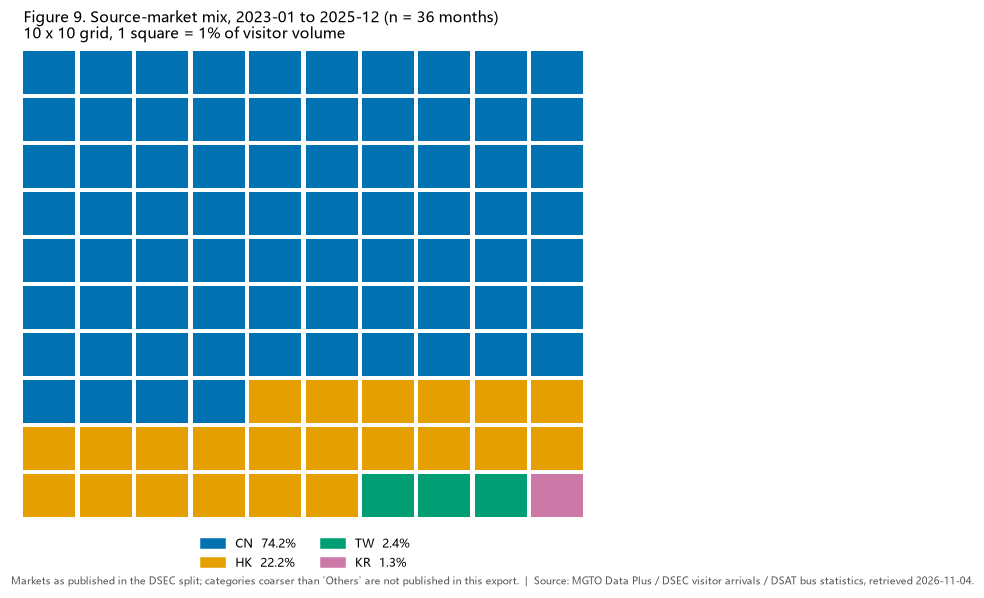

,market,share_pct,squares
0,CN,74.18,74
1,HK,22.16,22
2,TW,2.39,3
3,KR,1.27,1


In [20]:
mk = mkts.copy()
mk["month_dt"] = pd.to_datetime(dict(year=mk["Year"], month=mk["Month"], day=1))
mw = mk[(mk["month_dt"] >= WIN_START) & (mk["month_dt"] <= WIN_END)].copy()
mw["total"] = mw["SameDay"] + mw["OverNight"]
by_mkt = mw.groupby("Market")["total"].sum().sort_values(ascending=False)
share_pct = by_mkt / by_mkt.sum() * 100

counts = np.floor(share_pct.values).astype(int)
for i in np.argsort(-(share_pct.values - counts))[:100 - counts.sum()]:
    counts[i] += 1
colours = [BLUE, ORANGE, GREEN, PURPLE][:len(share_pct)]

fig, ax = plt.subplots(figsize=(5.4, 5.4))
k = 0
for ci, c in enumerate(colours):
    for _ in range(counts[ci]):
        r_, c_ = divmod(k, 10)
        k += 1
        ax.add_patch(Rectangle((c_, 9 - r_), 0.92, 0.92, color=c, lw=0))
ax.set_xlim(0, 10); ax.set_ylim(0, 10); ax.axis("off"); ax.grid(False)
ax.legend(handles=[Rectangle((0, 0), 1, 1, color=c) for c in colours],
          labels=[f"{n}  {v:.1f}%" for n, v in share_pct.items()],
          loc="upper center", bbox_to_anchor=(0.5, -0.02), frameon=False, ncol=2, fontsize=8)
ax.set_title(f"Figure 9. Source-market mix, 2023-01 to 2025-12 (n = 36 months)\n"
             f"10 x 10 grid, 1 square = 1% of visitor volume", loc="left", fontsize=9.5)
stamp(fig, "Markets as published in the DSEC split; categories coarser than 'Others' are not published in this export.")
fig.tight_layout()
save_fig(fig, "fig09_market_waffle.png")
plt.show()
display(pd.DataFrame({"market": share_pct.index, "share_pct": share_pct.round(2).values,
                      "squares": counts}))

saved  fig10_lag_crosscorrelation.png


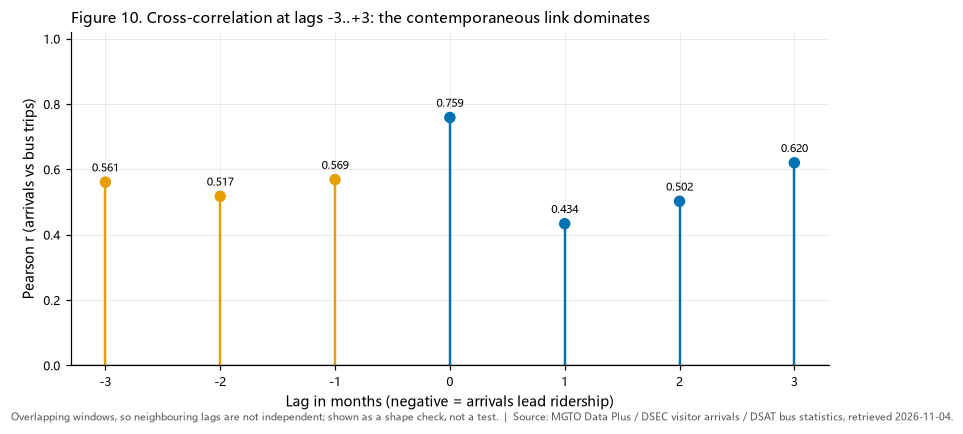

r by lag: {-3: np.float64(0.561), -2: np.float64(0.517), -1: np.float64(0.569), 0: np.float64(0.759), 1: np.float64(0.434), 2: np.float64(0.502), 3: np.float64(0.62)}
best lag: 0


In [21]:
lags = list(range(-3, 4))
rs = []
a = win["visitor_arrivals"].values
b = win["bus_monthly_trips"].values
for L in lags:
    if L >= 0:
        x, y = a[:len(a) - L] if L else a, b[L:]
    else:
        x, y = a[-L:], b[:len(b) + L]
    rs.append(stats.pearsonr(x, y)[0])

fig, ax = plt.subplots(figsize=(7.6, 3.9))
ax.vlines(lags, 0, rs, color=[BLUE if L >= 0 else ORANGE for L in lags], lw=1.6)
ax.scatter(lags, rs, color=[BLUE if L >= 0 else ORANGE for L in lags], s=42, zorder=3)
ax.axhline(0, color="#333333", lw=0.9)
ax.set_xticks(lags)
ax.set_xlabel("Lag in months (negative = arrivals lead ridership)")
ax.set_ylabel("Pearson r (arrivals vs bus trips)")
ax.set_ylim(0, 1.02)
ax.set_title("Figure 10. Cross-correlation at lags -3..+3: the contemporaneous link dominates", loc="left")
best = lags[int(np.argmax(rs))]
for L, r in zip(lags, rs):
    ax.annotate(f"{r:.3f}", (L, r), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=7.5)
stamp(fig, "Overlapping windows, so neighbouring lags are not independent; shown as a shape check, not a test.")
fig.tight_layout()
save_fig(fig, "fig10_lag_crosscorrelation.png")
plt.show()
print("r by lag:", {L: round(r, 3) for L, r in zip(lags, rs)})
print("best lag:", best)

,term,coef,std_err,t,p,coef_per_1000_visitors
0,const,1.003348e+07,4.159576e+06,2.4121,0.0216,NaN
1,visitor_arrivals,1.008600e+00,5.569000e-01,1.8113,0.0792,1008.6299
2,hotel_occ_pct,6.799301e+04,6.496118e+04,1.0467,0.3029,NaN


R2 = 0.589 | adj R2 = 0.564 | F p = 4.20e-07 | Durbin-Watson = 1.75
saved  fig11_regression_diagnostics.png


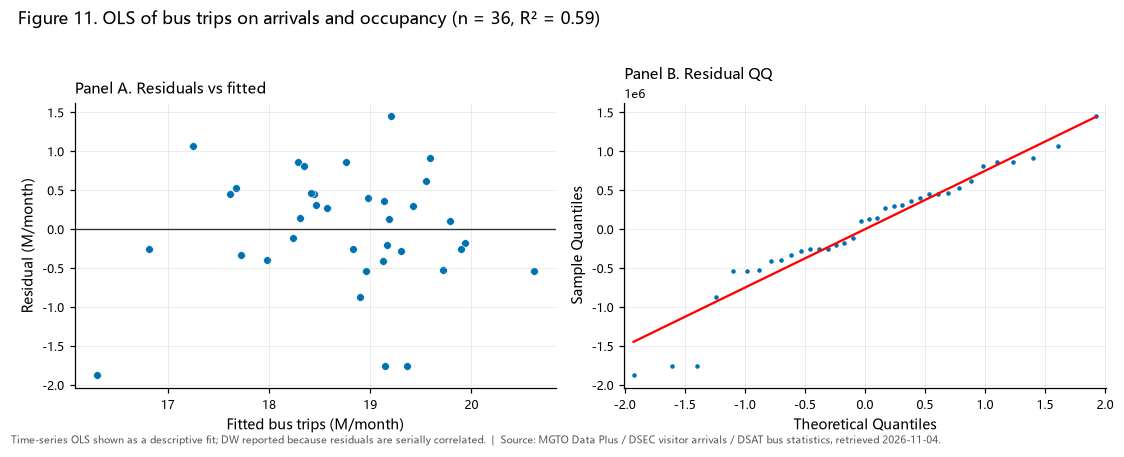

In [22]:
import statsmodels.api as sm
from statsmodels.stats.stattools import durbin_watson

X = sm.add_constant(win[["visitor_arrivals", "hotel_occ_pct"]])
m1 = sm.OLS(win["bus_monthly_trips"], X).fit()
dw = durbin_watson(m1.resid)

reg = pd.DataFrame({
    "term": ["const", "visitor_arrivals", "hotel_occ_pct"],
    "coef": m1.params.values,
    "std_err": m1.bse.values,
    "t": m1.tvalues.values,
    "p": m1.pvalues.values,
})
reg["coef_per_1000_visitors"] = [np.nan, reg.loc[1, "coef"] * 1000, np.nan]
display(reg.round(4))
print(f"R2 = {m1.rsquared:.3f} | adj R2 = {m1.rsquared_adj:.3f} | F p = {m1.f_pvalue:.2e} | Durbin-Watson = {dw:.2f}")

fig, ax = plt.subplots(1, 2, figsize=(10.2, 3.9))
ax[0].scatter(m1.fittedvalues / 1e6, m1.resid / 1e6, color=BLUE, s=26, edgecolor="white", lw=0.4)
ax[0].axhline(0, color="#333333", lw=0.9)
ax[0].set_xlabel("Fitted bus trips (M/month)")
ax[0].set_ylabel("Residual (M/month)")
ax[0].set_title("Panel A. Residuals vs fitted", loc="left")
sm.qqplot(m1.resid, line="s", ax=ax[1], markerfacecolor=BLUE, markeredgecolor="white", markersize=4)
ax[1].set_title("Panel B. Residual QQ", loc="left")
fig.suptitle(f"Figure 11. OLS of bus trips on arrivals and occupancy (n = 36, R\u00b2 = {m1.rsquared:.2f})",
             x=0.01, ha="left", y=1.02)
stamp(fig, "Time-series OLS shown as a descriptive fit; DW reported because residuals are serially correlated.")
fig.tight_layout()
save_fig(fig, "fig11_regression_diagnostics.png")
plt.show()

saved  fig12_dashboard_preview.png


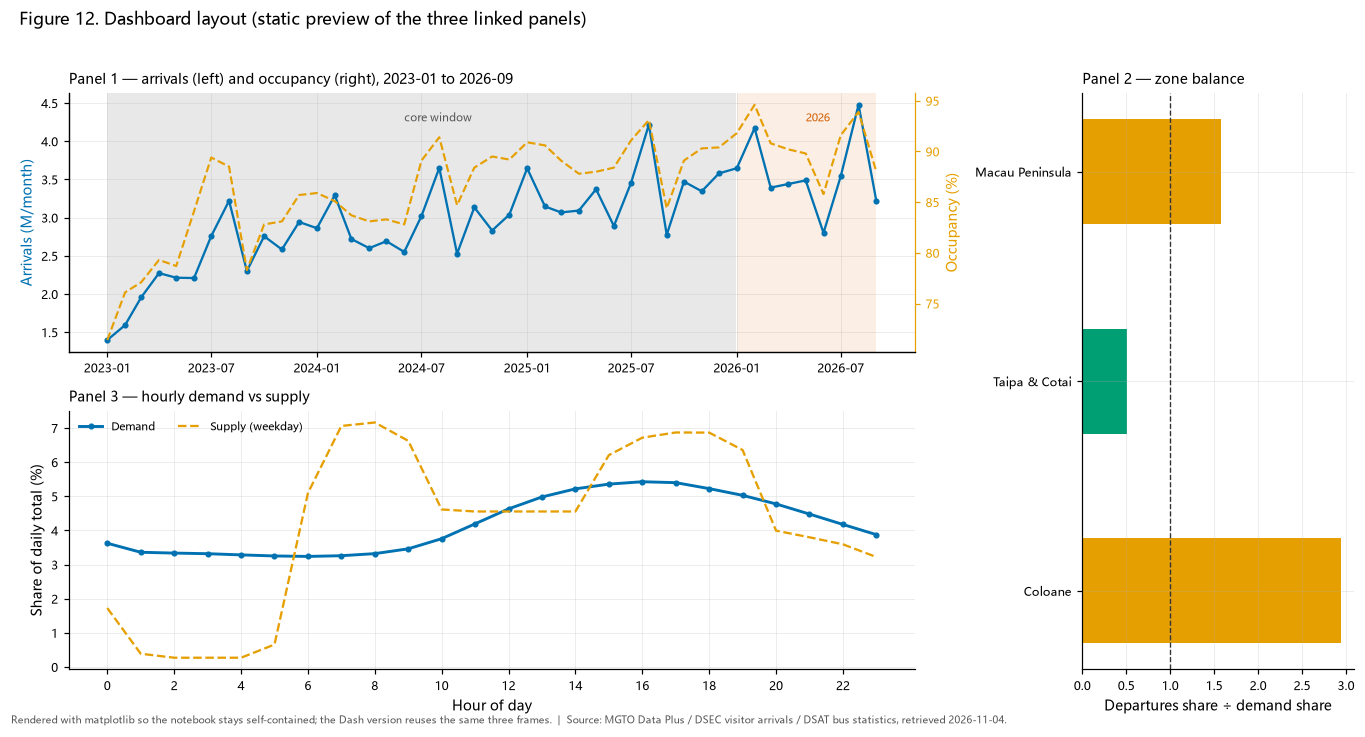

dash not installed in this kernel -> static preview only ( ModuleNotFoundError )


In [23]:
# Dashboard: the deliverable is a static composition that mirrors the Dash layout,
# so the notebook needs neither a live server nor a browser.
mosaic = [["a", "a", "b"], ["c", "c", "b"]]
fig, axd = plt.subplot_mosaic(mosaic, figsize=(12.4, 6.4), gridspec_kw={"width_ratios": [1.25, 1.25, 1.0], "height_ratios": [1, 1]})

ax = axd["a"]
ax.plot(panel["month_dt"], panel["visitor_arrivals"] / 1e6, color=BLUE, lw=1.5, marker="o", ms=3, label="Arrivals (M)")
ax.axvspan(WIN_START, WIN_END, color=GREY, alpha=0.2, lw=0)
ax.axvspan(TS("2026-01-01"), TS("2026-09-01"), color=RED, alpha=0.10, lw=0)
ax.set_ylabel("Arrivals (M/month)", color=BLUE)
ax2 = ax.twinx()
ax2.plot(panel["month_dt"], panel["hotel_occ_pct"], color=ORANGE, lw=1.4, ls="--", label="Occupancy (%)")
ax2.set_ylabel("Occupancy (%)", color=ORANGE)
ax2.tick_params(axis="y", colors=ORANGE)
ax2.spines["right"].set_visible(True); ax2.spines["right"].set_color(ORANGE); ax2.grid(False)
ax.set_title("Panel 1 — arrivals (left) and occupancy (right), 2023-01 to 2026-09", loc="left", fontsize=9)
ax.text(TS("2024-06-01"), ax.get_ylim()[1] * 0.92, "core window", fontsize=7.5, color="#555555")
ax.text(TS("2026-05-01"), ax.get_ylim()[1] * 0.92, "2026", fontsize=7.5, color=RED)

ax = axd["b"]
ax.barh(zone["zone"], zone["supply_demand_ratio"],
        color=[GREEN if v < 1 else ORANGE for v in zone["supply_demand_ratio"]], height=0.5)
ax.axvline(1, color="#333333", ls="--", lw=0.9)
ax.invert_yaxis()
ax.set_xlabel("Departures share ÷ demand share")
ax.set_title("Panel 2 — zone balance", loc="left", fontsize=9)

ax = axd["c"]
ax.plot(hourly["hour"], hourly["demand_share_pct"], color=BLUE, lw=1.9, marker="o", ms=3, label="Demand")
ax.plot(hourly["hour"], hourly["supply_share_weekday_pct"], color=ORANGE, lw=1.5, ls="--", label="Supply (weekday)")
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("Hour of day")
ax.set_ylabel("Share of daily total (%)")
ax.set_title("Panel 3 — hourly demand vs supply", loc="left", fontsize=9)
ax.legend(frameon=False, fontsize=7.5, ncol=2)

fig.suptitle("Figure 12. Dashboard layout (static preview of the three linked panels)", x=0.01, ha="left", y=1.02)
stamp(fig, "Rendered with matplotlib so the notebook stays self-contained; the Dash version reuses the same three frames.")
fig.tight_layout()
save_fig(fig, "fig12_dashboard_preview.png")
plt.show()

try:
    import dash
    print("dash available:", dash.__version__)
except Exception as exc:
    print("dash not installed in this kernel -> static preview only (", type(exc).__name__, ")")

## 16. Quality gate — colour-blind safety, grayscale legibility, export register

Every PNG is re-opened, converted to luminance, and its tonal spread recorded: a figure whose grey version collapses to a single tone is not print-safe, whatever its colour version looks like. The final table is the export register.

In [24]:
from PIL import Image

palette = [BLUE, ORANGE, GREEN, RED, PURPLE, SKY]
print("Palette in use (Okabe-Ito):", {c: c for c in palette})
print("Luminance of each colour:", {c: round(np.asarray(Image.new("RGB", (1, 1), c).convert("L")).ravel()[0], 1) for c in palette})

gate = []
for p in sorted(FIG.glob("*.png")):
    if p.name.endswith("_gray.png"):
        continue
    im = Image.open(p).convert("RGB")
    g = im.convert("L")
    arr = np.asarray(g, dtype=float)
    gray_path = p.with_name(p.stem + "_gray.png")
    g.save(gray_path)
    gate.append({"figure": p.name, "px": f"{im.width}x{im.height}",
                 "kb": round(p.stat().st_size / 1024, 1),
                 "tone_sd": round(float(arr.std()), 1),
                 "distinct_levels": int(len(np.unique(arr))),
                 "print_safe": "yes" if arr.std() > 25 and len(np.unique(arr)) > 40 else "REVIEW"})

gate_df = pd.DataFrame(gate)
display(gate_df)
print("figures exported:", len(gate_df), "| needing review:", int((gate_df['print_safe'] == 'REVIEW').sum()))

Palette in use (Okabe-Ito): {'#0072B2': '#0072B2', '#E69F00': '#E69F00', '#009E73': '#009E73', '#D55E00': '#D55E00', '#CC79A7': '#CC79A7', '#56B4E9': '#56B4E9'}
Luminance of each colour: {'#0072B2': np.uint8(87), '#E69F00': np.uint8(162), '#009E73': np.uint8(106), '#D55E00': np.uint8(119), '#CC79A7': np.uint8(151), '#56B4E9': np.uint8(158)}


,figure,px,kb,tone_sd,distinct_levels,print_safe
0,fig01_arrivals_longrun.png,2123x929,211.5,35.9,256,yes
1,fig02_rq1_coupling.png,2284x1540,370.8,32.8,256,yes
2,fig02_zone_mismatch.png,2483x954,158.3,59.2,256,yes
3,fig03_hourly_mismatch.png,2124x969,181.9,33.9,256,yes
4,fig04_intensity_decline.png,2323x954,215.5,33.9,256,yes
5,fig05_seasonality_2026.png,2443x974,320.4,37.7,256,yes
6,fig05b_district_hour_heatmap.png,2081x1128,364.0,69.1,256,yes
7,fig06_quarter_profile.png,2562x913,182.4,33.1,256,yes
8,fig07_2026_level_vs_base.png,1885x849,114.3,58.2,256,yes
9,fig08_distribution_diagnostics.png,2522x840,188.6,35.7,256,yes


figures exported: 16 | needing review: 0


## 17. Closing checks

Re-assert the structural invariants after all heavy computation, so the notebook cannot finish in an inconsistent state.

In [25]:
assert len(win) == 36
assert win["q"].nunique() == 12
assert len(W) == 36 and W[["same_day", "overnight"]].notna().all().all()
assert abs(win["visitor_arrivals"].sum() - q36["visitor_arrivals_sum"].sum()) < 1e-6
assert full["month"].nunique() == 45
assert len(dh) == 25920
assert (audit_df["verdict"] == "PASS").all()

summary = pd.DataFrame([
    {"figure": "Figure 1", "file": "fig01_arrivals_longrun.png", "n": 225, "window": "2008-01..2026-09", "question": "Long-run collapse and recovery; defines the window"},
    {"figure": "Figure 2", "file": "fig02_rq1_coupling.png", "n": 36, "window": "2023-01..2025-12", "question": "RQ1: arrivals and occupancy co-move"},
    {"figure": "Figure 4", "file": "fig04_intensity_decline.png", "n": 36, "window": "2023-01..2025-12", "question": "Per-visitor bus intensity declines"},
    {"figure": "H1", "file": "fig_h1_correlation_matrix.png", "n": 36, "window": "2023-01..2025-12", "question": "Correlation structure behind H1-H3"},
    {"figure": "H2", "file": "fig_h2_scatter_matrix.png", "n": 36, "window": "2023-01..2025-12", "question": "Pairwise support for H2/H3"},
    {"figure": "Figure 5", "file": "fig05_seasonality_2026.png", "n": 45, "window": "2023-01..2026-09", "question": "RQ2: 2026 reproduces the seasonal shape"},
    {"figure": "Figure 6", "file": "fig06_quarter_profile.png", "n": 45, "window": "2023-01..2026-09", "question": "Quarterly profile with 2026 overlaid"},
    {"figure": "Figure 7", "file": "fig07_2026_level_vs_base.png", "n": 9, "window": "2026 vs 2023-2025", "question": "2026 level shift per month"},
    {"figure": "Figure 8", "file": "fig08_distribution_diagnostics.png", "n": 36, "window": "2023-01..2025-12", "question": "Distribution and normality checks"},
    {"figure": "Figure 2b", "file": "fig02_zone_mismatch.png", "n": 3, "window": "2026", "question": "Spatial demand-supply mismatch"},
    {"figure": "Figure 3", "file": "fig03_hourly_mismatch.png", "n": 24, "window": "2026", "question": "Hourly demand-supply mismatch"},
    {"figure": "Figure 5b", "file": "fig05b_district_hour_heatmap.png", "n": 20736, "window": "2023-01..2025-12", "question": "District x hour rhythm"},
    {"figure": "Figure 9", "file": "fig09_market_waffle.png", "n": 36, "window": "2023-01..2025-12", "question": "Source-market mix"},
    {"figure": "Figure 10", "file": "fig10_lag_crosscorrelation.png", "n": 36, "window": "2023-01..2025-12", "question": "Lead-lag check"},
    {"figure": "Figure 11", "file": "fig11_regression_diagnostics.png", "n": 36, "window": "2023-01..2025-12", "question": "Regression diagnostics"},
    {"figure": "Figure 12", "file": "fig12_dashboard_preview.png", "n": 45, "window": "mixed", "question": "Dashboard composition"},
])
summary["exists"] = [ (FIG / f).exists() for f in summary["file"] ]
display(summary)
assert summary["exists"].all(), summary[~summary["exists"]]
print("ALL CLOSING CHECKS PASSED —", len(summary), "figures on disk")

,figure,file,n,window,question,exists
0,Figure 1,fig01_arrivals_longrun.png,225,2008-01..2026-09,Long-run collapse and recovery; defines the wi...,True
1,Figure 2,fig02_rq1_coupling.png,36,2023-01..2025-12,RQ1: arrivals and occupancy co-move,True
2,Figure 4,fig04_intensity_decline.png,36,2023-01..2025-12,Per-visitor bus intensity declines,True
3,H1,fig_h1_correlation_matrix.png,36,2023-01..2025-12,Correlation structure behind H1-H3,True
4,H2,fig_h2_scatter_matrix.png,36,2023-01..2025-12,Pairwise support for H2/H3,True
5,Figure 5,fig05_seasonality_2026.png,45,2023-01..2026-09,RQ2: 2026 reproduces the seasonal shape,True
6,Figure 6,fig06_quarter_profile.png,45,2023-01..2026-09,Quarterly profile with 2026 overlaid,True
7,Figure 7,fig07_2026_level_vs_base.png,9,2026 vs 2023-2025,2026 level shift per month,True
8,Figure 8,fig08_distribution_diagnostics.png,36,2023-01..2025-12,Distribution and normality checks,True
9,Figure 2b,fig02_zone_mismatch.png,3,2026,Spatial demand-supply mismatch,True


ALL CLOSING CHECKS PASSED — 16 figures on disk
